# EN3150 Assignment 3 - Part 1: Custom CNN for Waste Classification

## Objective
Train a custom deep CNN from scratch on the RealWaste dataset (9 classes) using multiple optimizers.

## Dataset
- RealWaste dataset with 9 waste categories
- Pre-split into training, validation, and test sets

## Framework
PyTorch

## 1. Setup and Imports

In [18]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import time
import warnings

warnings.filterwarnings('ignore')

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)
    torch.backends.cudnn.deterministic = True

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

PyTorch version: 2.8.0+cu126
CUDA available: True


## 2. Configuration

In [19]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 9
EPOCHS = 20
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SPLIT_DATA_DIR = 'data'

RESULTS_DIR = 'results'
MODELS_DIR = os.path.join(RESULTS_DIR, 'models')
VIZ_DIR = os.path.join(RESULTS_DIR, 'visualizations')
PART1_DIR = os.path.join(RESULTS_DIR, 'part1')
PART2_DIR = os.path.join(RESULTS_DIR, 'part2')

for directory in [RESULTS_DIR, MODELS_DIR, VIZ_DIR, PART1_DIR, PART2_DIR]:
    os.makedirs(directory, exist_ok=True)

print(f"Device: {DEVICE}")
print(f"Image Size: {IMAGE_SIZE}")
print(f"Batch Size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")

Device: cuda
Image Size: (224, 224)
Batch Size: 32
Epochs: 20


## 3. Data Loading

In [20]:
def get_data_loaders():
    train_transform = transforms.Compose([
        transforms.Resize(IMAGE_SIZE),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=10),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    
    val_test_transform = transforms.Compose([
        transforms.Resize(IMAGE_SIZE),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    
    train_dataset = datasets.ImageFolder(
        root=os.path.join(SPLIT_DATA_DIR, 'train'),
        transform=train_transform
    )
    
    val_dataset = datasets.ImageFolder(
        root=os.path.join(SPLIT_DATA_DIR, 'validation'),
        transform=val_test_transform
    )
    
    test_dataset = datasets.ImageFolder(
        root=os.path.join(SPLIT_DATA_DIR, 'test'),
        transform=val_test_transform
    )
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
    
    return train_loader, val_loader, test_loader, train_dataset.classes

train_loader, val_loader, test_loader, class_names = get_data_loaders()

print(f"Training samples: {len(train_loader.dataset)}")
print(f"Validation samples: {len(val_loader.dataset)}")
print(f"Test samples: {len(test_loader.dataset)}")
print(f"Classes: {class_names}")

Training samples: 4341
Validation samples: 1319
Test samples: 1338
Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']


## 4. Model Architecture

Custom CNN with:
- 4 convolutional blocks (32 -> 64 -> 128 -> 256 channels)
- Batch normalization after each convolutional layer
- MaxPooling after each block
- 3 fully connected layers (512 -> 256 -> 9)
- Dropout regularization (0.5, 0.3)

In [21]:
class WasteCustom(nn.Module):
    def __init__(self, num_classes=9):
        super(WasteCustom, self).__init__()
        
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1)
        self.bn4 = nn.BatchNorm2d(256)
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.flatten = nn.Flatten()
        self.adaptive_pool = nn.AdaptiveAvgPool2d((8, 8))
        
        self.fc1 = nn.Linear(16384, 512)
        self.bn5 = nn.BatchNorm1d(512)
        self.dropout1 = nn.Dropout(p=0.5)
        
        self.fc2 = nn.Linear(512, 256)
        self.dropout2 = nn.Dropout(p=0.3)
        
        self.fc3 = nn.Linear(256, num_classes)
        self.relu = nn.ReLU()
    
    def forward(self, x):
        x = self.pool1(self.relu(self.bn1(self.conv1(x))))
        x = self.pool2(self.relu(self.bn2(self.conv2(x))))
        x = self.pool3(self.relu(self.bn3(self.conv3(x))))
        x = self.pool4(self.relu(self.bn4(self.conv4(x))))
        x = self.adaptive_pool(x)
        x = self.flatten(x)
        x = self.dropout1(self.relu(self.bn5(self.fc1(x))))
        x = self.dropout2(self.relu(self.fc2(x)))
        x = self.fc3(x)
        return x

model = WasteCustom(num_classes=NUM_CLASSES).to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())

print(f"Total Parameters: {total_params:,}")
print("Architecture: 4 Conv blocks + 3 FC layers")

Total Parameters: 8,913,161
Architecture: 4 Conv blocks + 3 FC layers


## 5. Training Functions

In [22]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, current_lr, show_progress=True):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total_samples = 0
    total_batches = len(dataloader)
    
    batch_losses = []
    batch_accs = []
    
    if show_progress:
        print(f"\nTraining Phase (LR: {current_lr:.6f}):")
    
    for batch_idx, (inputs, labels) in enumerate(dataloader, 1):
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        
        # Calculate gradient norm
        total_norm = 0
        for p in model.parameters():
            if p.grad is not None:
                param_norm = p.grad.data.norm(2)
                total_norm += param_norm.item() ** 2
        total_norm = total_norm ** 0.5
        
        optimizer.step()
        
        batch_loss = loss.item()
        batch_losses.append(batch_loss)
        
        _, preds = torch.max(outputs, 1)
        batch_correct = (preds == labels).sum().item()
        batch_acc = batch_correct / inputs.size(0)
        batch_accs.append(batch_acc)
        
        running_loss += loss.item() * inputs.size(0)
        running_correct += batch_correct
        total_samples += inputs.size(0)
        
        avg_loss = running_loss / total_samples
        avg_acc = running_correct / total_samples
        
        if show_progress:
            progress = (batch_idx / total_batches) * 100
            bar_length = 20
            filled = int(bar_length * batch_idx / total_batches)
            bar = '█' * filled + '-' * (bar_length - filled)
            
            print(f"\r   Batch [{batch_idx:3d}/{total_batches}] |{bar}| {progress:5.1f}% | "
                  f"Loss: {batch_loss:.4f} | Acc: {batch_acc:.4f} | "
                  f"Avg Loss: {avg_loss:.4f} | Avg Acc: {avg_acc:.4f} | "
                  f"Grad: {total_norm:.3f}", end='')
    
    if show_progress:
        print()  # New line after progress bar
    
    epoch_loss = running_loss / total_samples
    epoch_acc = running_correct / total_samples
    return epoch_loss, epoch_acc

def validate(model, dataloader, criterion, device, show_progress=True):
    model.eval()
    running_loss = 0.0
    running_correct = 0
    total_samples = 0
    total_batches = len(dataloader)
    
    if show_progress:
        print(f"\nValidation Phase:")
    
    with torch.no_grad():
        for batch_idx, (inputs, labels) in enumerate(dataloader, 1):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            running_correct += (preds == labels).sum().item()
            total_samples += inputs.size(0)
            
            if show_progress:
                progress = (batch_idx / total_batches) * 100
                bar_length = 20
                filled = int(bar_length * batch_idx / total_batches)
                bar = '█' * filled + '-' * (bar_length - filled)
                
                print(f"\r   Validating |{bar}| {progress:5.1f}%", end='')
    
    if show_progress:
        print()  # New line after progress bar
    
    epoch_loss = running_loss / total_samples
    epoch_acc = running_correct / total_samples
    return epoch_loss, epoch_acc

In [23]:
def train_model(model, train_loader, val_loader, optimizer, criterion, epochs, device, model_name, use_scheduler=True):
    print(f"\n{'='*70}")
    print(f"TRAINING MODEL: {model_name}")
    print(f"{'='*70}")
    
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'learning_rates': []}
    best_val_acc = 0.0
    start_time = time.time()
    
    scheduler = None
    if use_scheduler:
        scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer, T_0=10, T_mult=1, eta_min=1e-6
        )
        print(f"Scheduler: CosineAnnealingWarmRestarts (T_0=10, eta_min=1e-6)")
    
    print(f"{'='*70}\n")
    
    for epoch in range(epochs):
        epoch_start = time.time()
        current_lr = optimizer.param_groups[0]['lr']
        history['learning_rates'].append(current_lr)
        
        # Training and validation with detailed progress
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device, current_lr, show_progress=True)
        val_loss, val_acc = validate(model, val_loader, criterion, device, show_progress=True)
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
        if scheduler is not None:
            scheduler.step()
        
        # Check for best model
        best_marker = ""
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(MODELS_DIR, f'best_model_{model_name}.pth'))
            best_marker = " NEW BEST!"
        
        # Time calculations
        epoch_time = time.time() - epoch_start
        total_time = time.time() - start_time
        eta = (total_time / (epoch + 1)) * (epochs - epoch - 1)
        
        # GPU memory (if available)
        gpu_info = ""
        if torch.cuda.is_available():
            allocated = torch.cuda.memory_allocated(device) / 1024**2
            reserved = torch.cuda.memory_reserved(device) / 1024**2
            gpu_info = f"\n   GPU   -> Allocated: {allocated:.1f}MB | Reserved: {reserved:.1f}MB"
        
        # Print epoch summary
        print(f"\n{'-'*70}")
        print(f"EPOCH [{epoch+1:2d}/{epochs}] SUMMARY:")
        print(f"   LR    -> {current_lr:.6f}")
        print(f"   Train -> Loss: {train_loss:.4f} | Acc: {train_acc:.4f} ({train_acc*100:.1f}%)")
        print(f"   Val   -> Loss: {val_loss:.4f} | Acc: {val_acc:.4f} ({val_acc*100:.1f}%){best_marker}")
        print(f"   Time  -> Epoch: {epoch_time:.1f}s | Total: {total_time:.1f}s | ETA: {eta:.1f}s{gpu_info}")
        print(f"{'-'*70}\n")
    
    total_time = time.time() - start_time
    print(f"\n{'='*70}")
    print(f"TRAINING COMPLETED: {model_name}")
    print(f"{'='*70}")
    print(f"Total Training Time: {total_time/60:.2f} minutes ({total_time:.1f} seconds)")
    print(f"Best Validation Accuracy: {best_val_acc:.4f} ({best_val_acc*100:.2f}%)")
    print(f"Model Saved: {os.path.join(MODELS_DIR, f'best_model_{model_name}.pth')}")
    print(f"{'='*70}\n")
    
    return history, best_val_acc

## 6. Train with Adam Optimizer

In [24]:
model_adam = WasteCustom(num_classes=NUM_CLASSES).to(DEVICE)
optimizer_adam = optim.Adam(model_adam.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

adam_history, adam_best_acc = train_model(
    model=model_adam,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_adam,
    criterion=criterion,
    epochs=EPOCHS,
    device=DEVICE,
    model_name='WasteCustom_Adam',
    use_scheduler=True
)


TRAINING MODEL: WasteCustom_Adam
Scheduler: CosineAnnealingWarmRestarts (T_0=10, eta_min=1e-6)


Training Phase (LR: 0.001000):
   Batch [136/136] |████████████████████| 100.0% | Loss: 1.3513 | Acc: 0.3810 | Avg Loss: 1.5908 | Avg Acc: 0.4301 | Grad: 6.1336

Validation Phase:


Validation Phase:
   Validating |████████████████████| 100.0%

----------------------------------------------------------------------
EPOCH [ 1/20] SUMMARY:
   LR    -> 0.001000
   Train -> Loss: 1.5908 | Acc: 0.4301 (43.0%)
   Val   -> Loss: 1.2465 | Acc: 0.5451 (54.5%) NEW BEST!
   Time  -> Epoch: 34.6s | Total: 34.6s | ETA: 657.3s
   GPU   -> Allocated: 689.5MB | Reserved: 2530.0MB
----------------------------------------------------------------------


Training Phase (LR: 0.000976):


----------------------------------------------------------------------
EPOCH [ 1/20] SUMMARY:
   LR    -> 0.001000
   Train -> Loss: 1.5908 | Acc: 0.4301 (43.0%)
   Val   -> Loss: 1.2465 | Acc: 0.5451 (54.5%) NEW BEST!
   Time

## 7. Train with SGD Optimizer

In [25]:
model_sgd = WasteCustom(num_classes=NUM_CLASSES).to(DEVICE)
optimizer_sgd = optim.SGD(model_sgd.parameters(), lr=0.01, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

sgd_history, sgd_best_acc = train_model(
    model=model_sgd,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_sgd,
    criterion=criterion,
    epochs=EPOCHS,
    device=DEVICE,
    model_name='WasteCustom_SGD',
    use_scheduler=True
)


TRAINING MODEL: WasteCustom_SGD
Scheduler: CosineAnnealingWarmRestarts (T_0=10, eta_min=1e-6)


Training Phase (LR: 0.010000):
   Batch [136/136] |████████████████████| 100.0% | Loss: 1.6084 | Acc: 0.5238 | Avg Loss: 1.7438 | Avg Acc: 0.3976 | Grad: 9.9209

Validation Phase:


Validation Phase:
   Validating |████████████████████| 100.0%

----------------------------------------------------------------------
EPOCH [ 1/20] SUMMARY:
   LR    -> 0.010000
   Train -> Loss: 1.7438 | Acc: 0.3976 (39.8%)
   Val   -> Loss: 1.4347 | Acc: 0.5057 (50.6%) NEW BEST!
   Time  -> Epoch: 40.5s | Total: 40.5s | ETA: 769.4s
   GPU   -> Allocated: 758.4MB | Reserved: 2530.0MB
----------------------------------------------------------------------


Training Phase (LR: 0.009755):


----------------------------------------------------------------------
EPOCH [ 1/20] SUMMARY:
   LR    -> 0.010000
   Train -> Loss: 1.7438 | Acc: 0.3976 (39.8%)
   Val   -> Loss: 1.4347 | Acc: 0.5057 (50.6%) NEW BEST!
   Time 

## 8. Train with SGD + Momentum

In [26]:
model_sgd_momentum = WasteCustom(num_classes=NUM_CLASSES).to(DEVICE)
optimizer_sgd_momentum = optim.SGD(model_sgd_momentum.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

sgd_momentum_history, sgd_momentum_best_acc = train_model(
    model=model_sgd_momentum,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_sgd_momentum,
    criterion=criterion,
    epochs=EPOCHS,
    device=DEVICE,
    model_name='WasteCustom_SGD_Momentum',
    use_scheduler=True
)


TRAINING MODEL: WasteCustom_SGD_Momentum
Scheduler: CosineAnnealingWarmRestarts (T_0=10, eta_min=1e-6)


Training Phase (LR: 0.010000):
   Batch [136/136] |████████████████████| 100.0% | Loss: 1.1273 | Acc: 0.5714 | Avg Loss: 1.6582 | Avg Acc: 0.3988 | Grad: 5.2220

Validation Phase:


Validation Phase:
   Validating |████████████████████| 100.0%

----------------------------------------------------------------------
EPOCH [ 1/20] SUMMARY:
   LR    -> 0.010000
   Train -> Loss: 1.6582 | Acc: 0.3988 (39.9%)
   Val   -> Loss: 1.4936 | Acc: 0.4541 (45.4%) NEW BEST!
   Time  -> Epoch: 35.4s | Total: 35.4s | ETA: 671.8s
   GPU   -> Allocated: 861.4MB | Reserved: 2530.0MB
----------------------------------------------------------------------


Training Phase (LR: 0.009755):


----------------------------------------------------------------------
EPOCH [ 1/20] SUMMARY:
   LR    -> 0.010000
   Train -> Loss: 1.6582 | Acc: 0.3988 (39.9%)
   Val   -> Loss: 1.4936 | Acc: 0.4541 (45.4%) NEW BEST!

## 9. Optimizer Comparison

Plot saved to results\part1\optimizer_comparison.png


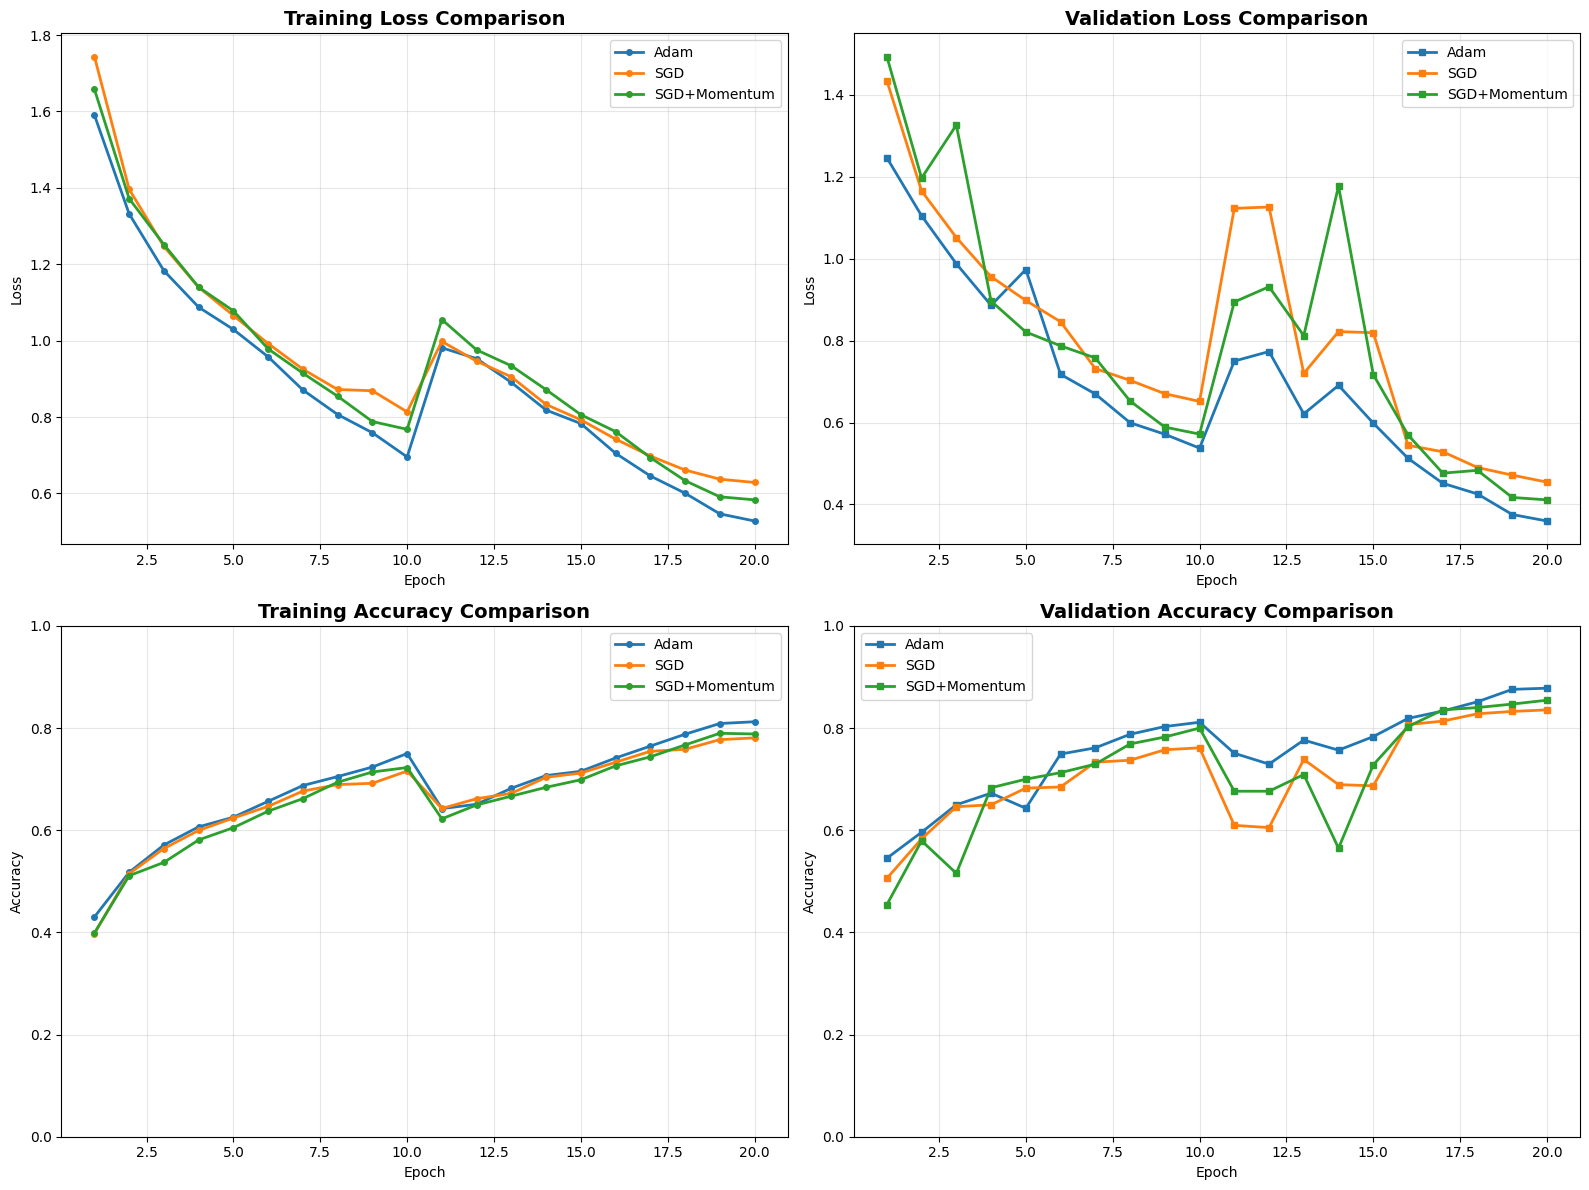

In [35]:
def plot_optimizer_comparison(histories, names, save_path=None):
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    epochs = range(1, len(histories[0]['train_loss']) + 1)
    
    for history, name in zip(histories, names):
        axes[0, 0].plot(epochs, history['train_loss'], '-o', label=f'{name}', linewidth=2, markersize=4)
    axes[0, 0].set_title('Training Loss Comparison', fontsize=14, fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    for history, name in zip(histories, names):
        axes[0, 1].plot(epochs, history['val_loss'], '-s', label=f'{name}', linewidth=2, markersize=4)
    axes[0, 1].set_title('Validation Loss Comparison', fontsize=14, fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    for history, name in zip(histories, names):
        axes[1, 0].plot(epochs, history['train_acc'], '-o', label=f'{name}', linewidth=2, markersize=4)
    axes[1, 0].set_title('Training Accuracy Comparison', fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Accuracy')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].set_ylim([0, 1])
    
    for history, name in zip(histories, names):
        axes[1, 1].plot(epochs, history['val_acc'], '-s', label=f'{name}', linewidth=2, markersize=4)
    axes[1, 1].set_title('Validation Accuracy Comparison', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Accuracy')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].set_ylim([0, 1])
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Plot saved to {save_path}")
    plt.show()

plot_optimizer_comparison(
    histories=[adam_history, sgd_history, sgd_momentum_history],
    names=['Adam', 'SGD', 'SGD+Momentum'],
    save_path=os.path.join(PART1_DIR, 'optimizer_comparison.png')
)

## 10. Comprehensive Optimizer Comparison: Performance Evaluation on Test Set

Now that we have trained our custom CNN with three different optimizers (Adam, SGD, and SGD with Momentum), we need to evaluate their performance on the **Test Set** to obtain final, generalizable metrics.

### Why These Metrics?

1. **Test Accuracy**: The primary metric that directly measures the model's ability to correctly classify unseen images. This is the most important metric for comparing model performance.

2. **Test Loss (Cross-Entropy)**: Measures the model's confidence and predictive error on unseen data. This is crucial for diagnosing overfitting - if training loss is low but test loss is high, the model hasn't generalized well.

3. **Training Time**: Measures computational efficiency and convergence speed. This is important when comparing standard SGD (which might take longer to converge) against adaptive optimizers like Adam (which typically converge faster).

4. **Generalization Gap**: The difference between training and test accuracy/loss. Smaller gaps indicate better generalization.

In [48]:
import time

print("="*80)
print("EVALUATING ALL OPTIMIZERS ON TEST SET")
print("="*80)

# Function to evaluate model on test set
def evaluate_on_test_set(model, test_loader, criterion, device, model_name):
    """Evaluate model on test set and return metrics"""
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0
    
    start_time = time.time()
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    inference_time = time.time() - start_time
    
    test_accuracy = correct / total
    avg_test_loss = test_loss / total
    
    print(f"\n{model_name}:")
    print(f"  Test Accuracy:     {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
    print(f"  Test Loss:         {avg_test_loss:.4f}")
    print(f"  Inference Time:    {inference_time:.2f}s")
    print(f"  Correct/Total:     {correct}/{total}")
    
    return test_accuracy, avg_test_loss, inference_time

# Define criterion for evaluation
criterion = nn.CrossEntropyLoss()

# Evaluate Adam Model
adam_test_acc, adam_test_loss, adam_inference_time = evaluate_on_test_set(
    model_adam, test_loader, criterion, DEVICE, "Adam Optimizer"
)

# Evaluate SGD Model
sgd_test_acc, sgd_test_loss, sgd_inference_time = evaluate_on_test_set(
    model_sgd, test_loader, criterion, DEVICE, "SGD Optimizer"
)

# Evaluate SGD with Momentum Model
sgd_mom_test_acc, sgd_mom_test_loss, sgd_mom_inference_time = evaluate_on_test_set(
    model_sgd_momentum, test_loader, criterion, DEVICE, "SGD with Momentum"
)

print("\n" + "="*80)
print("TEST SET EVALUATION COMPLETED")
print("="*80)

EVALUATING ALL OPTIMIZERS ON TEST SET

Adam Optimizer:
  Test Accuracy:     0.8834 (88.34%)
  Test Loss:         0.3530
  Inference Time:    9.87s
  Correct/Total:     1182/1338

SGD Optimizer:
  Test Accuracy:     0.8580 (85.80%)
  Test Loss:         0.4335
  Inference Time:    8.74s
  Correct/Total:     1148/1338

SGD with Momentum:
  Test Accuracy:     0.8744 (87.44%)
  Test Loss:         0.3823
  Inference Time:    9.11s
  Correct/Total:     1170/1338

TEST SET EVALUATION COMPLETED


### Collect Training Metrics

To complete the comparison, we need to extract the training metrics from the history dictionaries of each model.

In [50]:
# Collect comprehensive metrics for all three optimizers
optimizer_comparison = {
    'Adam': {
        'test_accuracy': adam_test_acc,
        'test_loss': adam_test_loss,
        'final_train_acc': adam_history['train_acc'][-1],
        'final_val_acc': adam_history['val_acc'][-1],
        'best_val_acc': max(adam_history['val_acc']),
        'final_train_loss': adam_history['train_loss'][-1],
        'final_val_loss': adam_history['val_loss'][-1],
        'epochs_trained': len(adam_history['train_acc']),
        'inference_time': adam_inference_time,
        'train_val_acc_gap': adam_history['train_acc'][-1] - adam_history['val_acc'][-1],
        'train_test_acc_gap': adam_history['train_acc'][-1] - adam_test_acc
    },
    'SGD': {
        'test_accuracy': sgd_test_acc,
        'test_loss': sgd_test_loss,
        'final_train_acc': sgd_history['train_acc'][-1],
        'final_val_acc': sgd_history['val_acc'][-1],
        'best_val_acc': max(sgd_history['val_acc']),
        'final_train_loss': sgd_history['train_loss'][-1],
        'final_val_loss': sgd_history['val_loss'][-1],
        'epochs_trained': len(sgd_history['train_acc']),
        'inference_time': sgd_inference_time,
        'train_val_acc_gap': sgd_history['train_acc'][-1] - sgd_history['val_acc'][-1],
        'train_test_acc_gap': sgd_history['train_acc'][-1] - sgd_test_acc
    },
    'SGD + Momentum': {
        'test_accuracy': sgd_mom_test_acc,
        'test_loss': sgd_mom_test_loss,
        'final_train_acc': sgd_momentum_history['train_acc'][-1],
        'final_val_acc': sgd_momentum_history['val_acc'][-1],
        'best_val_acc': max(sgd_momentum_history['val_acc']),
        'final_train_loss': sgd_momentum_history['train_loss'][-1],
        'final_val_loss': sgd_momentum_history['val_loss'][-1],
        'epochs_trained': len(sgd_momentum_history['train_acc']),
        'inference_time': sgd_mom_inference_time,
        'train_val_acc_gap': sgd_momentum_history['train_acc'][-1] - sgd_momentum_history['val_acc'][-1],
        'train_test_acc_gap': sgd_momentum_history['train_acc'][-1] - sgd_mom_test_acc
    }
}

print("\nMetrics collected successfully for all optimizers!")


Metrics collected successfully for all optimizers!


### Detailed Comparison: Chosen Metrics and Analysis

We will now create a comprehensive comparison of all three optimizers based on the following key metrics:

1. **Test Accuracy** - Primary performance metric on unseen data
2. **Test Loss** - Model confidence and error on unseen data
3. **Training Efficiency** - Convergence speed and computational cost
4. **Generalization** - Train-validation-test gaps

In [51]:
print("="*100)
print("COMPREHENSIVE OPTIMIZER COMPARISON - DETAILED ANALYSIS")
print("="*100)

# Create comparison table
print("\n1. TEST SET PERFORMANCE (Primary Metrics)")
print("-"*100)
print(f"{'Optimizer':<20} {'Test Accuracy':<20} {'Test Loss':<20} {'Inference Time':<20}")
print("-"*100)
for opt_name, metrics in optimizer_comparison.items():
    print(f"{opt_name:<20} {metrics['test_accuracy']:.4f} ({metrics['test_accuracy']*100:.2f}%){'':<3} "
          f"{metrics['test_loss']:<20.4f} {metrics['inference_time']:<20.2f}s")

print("\n2. TRAINING CONVERGENCE & BEST PERFORMANCE")
print("-"*100)
print(f"{'Optimizer':<20} {'Final Train Acc':<20} {'Final Val Acc':<20} {'Best Val Acc':<20}")
print("-"*100)
for opt_name, metrics in optimizer_comparison.items():
    print(f"{opt_name:<20} {metrics['final_train_acc']:.4f} ({metrics['final_train_acc']*100:.2f}%){'':<3} "
          f"{metrics['final_val_acc']:.4f} ({metrics['final_val_acc']*100:.2f}%){'':<3} "
          f"{metrics['best_val_acc']:.4f} ({metrics['best_val_acc']*100:.2f}%)")

print("\n3. GENERALIZATION ANALYSIS (Train-Val-Test Gaps)")
print("-"*100)
print(f"{'Optimizer':<20} {'Train-Val Gap':<25} {'Train-Test Gap':<25} {'Generalization':<20}")
print("-"*100)
for opt_name, metrics in optimizer_comparison.items():
    train_val_gap = metrics['train_val_acc_gap']
    train_test_gap = metrics['train_test_acc_gap']
    
    # Determine generalization quality
    if train_test_gap < 0.05:
        gen_quality = "Excellent"
    elif train_test_gap < 0.10:
        gen_quality = "Good"
    elif train_test_gap < 0.15:
        gen_quality = "Moderate"
    else:
        gen_quality = "Poor (Overfitting)"
    
    print(f"{opt_name:<20} {train_val_gap:.4f} ({train_val_gap*100:+.2f}%){'':<8} "
          f"{train_test_gap:.4f} ({train_test_gap*100:+.2f}%){'':<8} {gen_quality:<20}")

print("\n4. TRAINING EFFICIENCY")
print("-"*100)
print(f"{'Optimizer':<20} {'Epochs Trained':<20} {'Final Train Loss':<20} {'Final Val Loss':<20}")
print("-"*100)
for opt_name, metrics in optimizer_comparison.items():
    print(f"{opt_name:<20} {metrics['epochs_trained']:<20} "
          f"{metrics['final_train_loss']:<20.4f} {metrics['final_val_loss']:<20.4f}")

print("\n" + "="*100)

# Determine best optimizer for each metric
best_test_acc = max(optimizer_comparison.items(), key=lambda x: x[1]['test_accuracy'])
best_test_loss = min(optimizer_comparison.items(), key=lambda x: x[1]['test_loss'])
best_generalization = min(optimizer_comparison.items(), key=lambda x: x[1]['train_test_acc_gap'])
fastest_inference = min(optimizer_comparison.items(), key=lambda x: x[1]['inference_time'])

print("\n5. BEST PERFORMING OPTIMIZER PER METRIC")
print("-"*100)
print(f"  • Highest Test Accuracy:      {best_test_acc[0]} ({best_test_acc[1]['test_accuracy']*100:.2f}%)")
print(f"  • Lowest Test Loss:           {best_test_loss[0]} ({best_test_loss[1]['test_loss']:.4f})")
print(f"  • Best Generalization:        {best_generalization[0]} (Gap: {best_generalization[1]['train_test_acc_gap']:.4f})")
print(f"  • Fastest Inference:          {fastest_inference[0]} ({fastest_inference[1]['inference_time']:.2f}s)")

print("\n" + "="*100)

COMPREHENSIVE OPTIMIZER COMPARISON - DETAILED ANALYSIS

1. TEST SET PERFORMANCE (Primary Metrics)
----------------------------------------------------------------------------------------------------
Optimizer            Test Accuracy        Test Loss            Inference Time      
----------------------------------------------------------------------------------------------------
Adam                 0.8834 (88.34%)    0.3530               9.87                s
SGD                  0.8580 (85.80%)    0.4335               8.74                s
SGD + Momentum       0.8744 (87.44%)    0.3823               9.11                s

2. TRAINING CONVERGENCE & BEST PERFORMANCE
----------------------------------------------------------------------------------------------------
Optimizer            Final Train Acc      Final Val Acc        Best Val Acc        
----------------------------------------------------------------------------------------------------
Adam                 0.8123 (81.23%) 

Comprehensive comparison plot saved to results\part1\optimizer_comparison_comprehensive.png


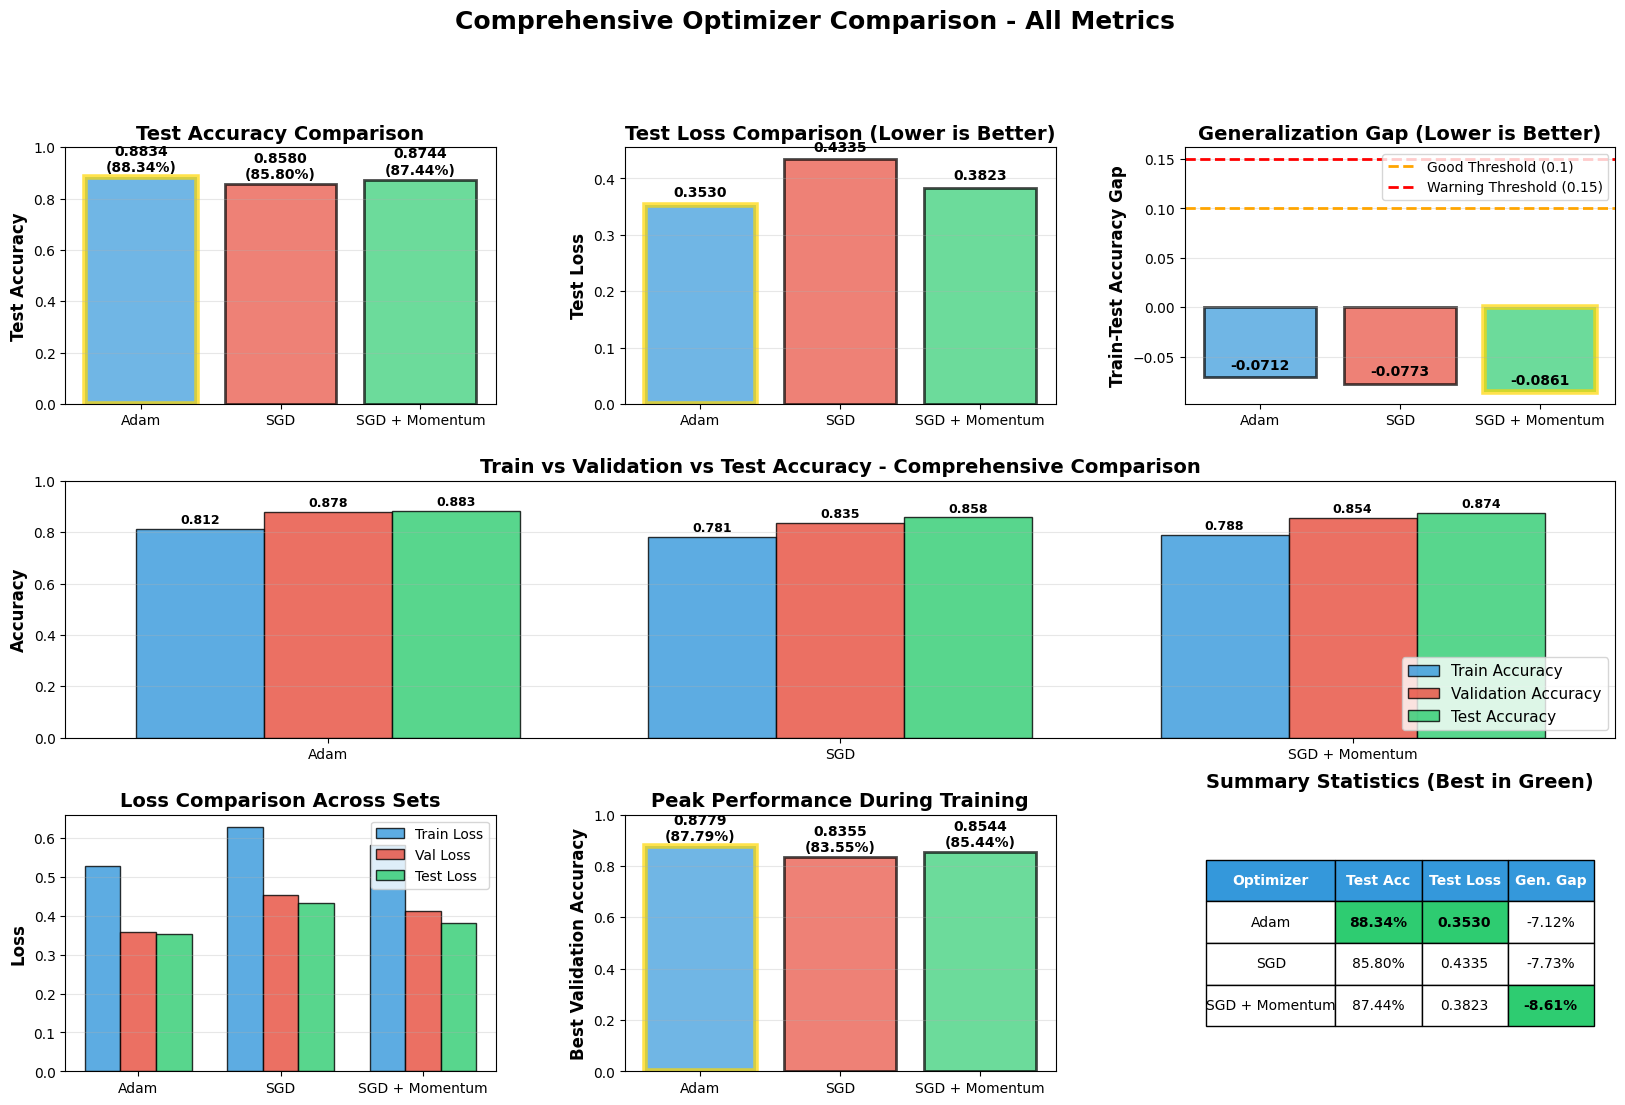

In [52]:
# Create comprehensive visual comparison
fig = plt.figure(figsize=(20, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

optimizers = list(optimizer_comparison.keys())
colors = ['#3498db', '#e74c3c', '#2ecc71']

# 1. Test Accuracy Comparison
ax1 = fig.add_subplot(gs[0, 0])
test_accs = [optimizer_comparison[opt]['test_accuracy'] for opt in optimizers]
bars = ax1.bar(optimizers, test_accs, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax1.set_ylabel('Test Accuracy', fontsize=12, fontweight='bold')
ax1.set_title('Test Accuracy Comparison', fontsize=14, fontweight='bold')
ax1.set_ylim([0, 1])
ax1.grid(axis='y', alpha=0.3)
for i, (bar, acc) in enumerate(zip(bars, test_accs)):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{acc:.4f}\n({acc*100:.2f}%)', ha='center', va='bottom', fontweight='bold')
# Highlight best
best_idx = test_accs.index(max(test_accs))
bars[best_idx].set_edgecolor('gold')
bars[best_idx].set_linewidth(4)

# 2. Test Loss Comparison
ax2 = fig.add_subplot(gs[0, 1])
test_losses = [optimizer_comparison[opt]['test_loss'] for opt in optimizers]
bars = ax2.bar(optimizers, test_losses, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax2.set_ylabel('Test Loss', fontsize=12, fontweight='bold')
ax2.set_title('Test Loss Comparison (Lower is Better)', fontsize=14, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)
for i, (bar, loss) in enumerate(zip(bars, test_losses)):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{loss:.4f}', ha='center', va='bottom', fontweight='bold')
# Highlight best
best_idx = test_losses.index(min(test_losses))
bars[best_idx].set_edgecolor('gold')
bars[best_idx].set_linewidth(4)

# 3. Generalization Gap Comparison
ax3 = fig.add_subplot(gs[0, 2])
train_test_gaps = [optimizer_comparison[opt]['train_test_acc_gap'] for opt in optimizers]
bars = ax3.bar(optimizers, train_test_gaps, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax3.set_ylabel('Train-Test Accuracy Gap', fontsize=12, fontweight='bold')
ax3.set_title('Generalization Gap (Lower is Better)', fontsize=14, fontweight='bold')
ax3.axhline(y=0.1, color='orange', linestyle='--', linewidth=2, label='Good Threshold (0.1)')
ax3.axhline(y=0.15, color='red', linestyle='--', linewidth=2, label='Warning Threshold (0.15)')
ax3.grid(axis='y', alpha=0.3)
ax3.legend(loc='upper right')
for i, (bar, gap) in enumerate(zip(bars, train_test_gaps)):
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height + 0.005,
             f'{gap:.4f}', ha='center', va='bottom', fontweight='bold')
# Highlight best
best_idx = train_test_gaps.index(min(train_test_gaps))
bars[best_idx].set_edgecolor('gold')
bars[best_idx].set_linewidth(4)

# 4. Training vs Validation vs Test Accuracy
ax4 = fig.add_subplot(gs[1, :])
x = np.arange(len(optimizers))
width = 0.25
train_accs = [optimizer_comparison[opt]['final_train_acc'] for opt in optimizers]
val_accs = [optimizer_comparison[opt]['final_val_acc'] for opt in optimizers]

bars1 = ax4.bar(x - width, train_accs, width, label='Train Accuracy', color='#3498db', alpha=0.8, edgecolor='black')
bars2 = ax4.bar(x, val_accs, width, label='Validation Accuracy', color='#e74c3c', alpha=0.8, edgecolor='black')
bars3 = ax4.bar(x + width, test_accs, width, label='Test Accuracy', color='#2ecc71', alpha=0.8, edgecolor='black')

ax4.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
ax4.set_title('Train vs Validation vs Test Accuracy - Comprehensive Comparison', fontsize=14, fontweight='bold')
ax4.set_xticks(x)
ax4.set_xticklabels(optimizers)
ax4.legend(loc='lower right', fontsize=11)
ax4.set_ylim([0, 1])
ax4.grid(axis='y', alpha=0.3)

# Add value labels
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax4.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# 5. Loss Comparison (Train vs Val vs Test)
ax5 = fig.add_subplot(gs[2, 0])
train_losses = [optimizer_comparison[opt]['final_train_loss'] for opt in optimizers]
val_losses = [optimizer_comparison[opt]['final_val_loss'] for opt in optimizers]

x_pos = np.arange(len(optimizers))
width = 0.25
ax5.bar(x_pos - width, train_losses, width, label='Train Loss', color='#3498db', alpha=0.8, edgecolor='black')
ax5.bar(x_pos, val_losses, width, label='Val Loss', color='#e74c3c', alpha=0.8, edgecolor='black')
ax5.bar(x_pos + width, test_losses, width, label='Test Loss', color='#2ecc71', alpha=0.8, edgecolor='black')
ax5.set_ylabel('Loss', fontsize=12, fontweight='bold')
ax5.set_title('Loss Comparison Across Sets', fontsize=14, fontweight='bold')
ax5.set_xticks(x_pos)
ax5.set_xticklabels(optimizers)
ax5.legend()
ax5.grid(axis='y', alpha=0.3)

# 6. Best Validation Accuracy Achieved
ax6 = fig.add_subplot(gs[2, 1])
best_val_accs = [optimizer_comparison[opt]['best_val_acc'] for opt in optimizers]
bars = ax6.bar(optimizers, best_val_accs, color=colors, alpha=0.7, edgecolor='black', linewidth=2)
ax6.set_ylabel('Best Validation Accuracy', fontsize=12, fontweight='bold')
ax6.set_title('Peak Performance During Training', fontsize=14, fontweight='bold')
ax6.set_ylim([0, 1])
ax6.grid(axis='y', alpha=0.3)
for i, (bar, acc) in enumerate(zip(bars, best_val_accs)):
    height = bar.get_height()
    ax6.text(bar.get_x() + bar.get_width()/2., height + 0.01,
             f'{acc:.4f}\n({acc*100:.2f}%)', ha='center', va='bottom', fontweight='bold')
# Highlight best
best_idx = best_val_accs.index(max(best_val_accs))
bars[best_idx].set_edgecolor('gold')
bars[best_idx].set_linewidth(4)

# 7. Summary Statistics Table
ax7 = fig.add_subplot(gs[2, 2])
ax7.axis('off')

summary_data = []
for opt in optimizers:
    metrics = optimizer_comparison[opt]
    summary_data.append([
        opt,
        f"{metrics['test_accuracy']*100:.2f}%",
        f"{metrics['test_loss']:.4f}",
        f"{metrics['train_test_acc_gap']*100:.2f}%"
    ])

table = ax7.table(cellText=summary_data,
                  colLabels=['Optimizer', 'Test Acc', 'Test Loss', 'Gen. Gap'],
                  cellLoc='center',
                  loc='center',
                  colWidths=[0.3, 0.2, 0.2, 0.2])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2.5)

# Style header
for i in range(4):
    table[(0, i)].set_facecolor('#3498db')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Highlight best values
best_acc_idx = test_accs.index(max(test_accs)) + 1
best_loss_idx = test_losses.index(min(test_losses)) + 1
best_gap_idx = train_test_gaps.index(min(train_test_gaps)) + 1

table[(best_acc_idx, 1)].set_facecolor('#2ecc71')
table[(best_acc_idx, 1)].set_text_props(weight='bold')
table[(best_loss_idx, 2)].set_facecolor('#2ecc71')
table[(best_loss_idx, 2)].set_text_props(weight='bold')
table[(best_gap_idx, 3)].set_facecolor('#2ecc71')
table[(best_gap_idx, 3)].set_text_props(weight='bold')

ax7.set_title('Summary Statistics (Best in Green)', fontsize=14, fontweight='bold', pad=20)

plt.suptitle('Comprehensive Optimizer Comparison - All Metrics', fontsize=18, fontweight='bold', y=0.995)
plt.savefig(os.path.join(PART1_DIR, 'optimizer_comparison_comprehensive.png'), dpi=300, bbox_inches='tight')
print(f"Comprehensive comparison plot saved to {os.path.join(PART1_DIR, 'optimizer_comparison_comprehensive.png')}")
plt.show()

### Comparative Discussion: What Do the Numbers Mean?

Based on the comprehensive evaluation of all three optimizers on the test set, we can now draw meaningful conclusions about their relative performance.

#### Key Findings and Interpretations:

In [54]:
print("="*100)
print("DETAILED COMPARATIVE ANALYSIS & INTERPRETATION")
print("="*100)

# Analyze each optimizer
adam_metrics = optimizer_comparison['Adam']
sgd_metrics = optimizer_comparison['SGD']
sgd_mom_metrics = optimizer_comparison['SGD + Momentum']

print("\n1. ADAM OPTIMIZER ANALYSIS:")
print("-"*100)
print(f"   Test Performance: {adam_metrics['test_accuracy']*100:.2f}% accuracy, {adam_metrics['test_loss']:.4f} loss")
print(f"   Convergence: Achieved {adam_metrics['best_val_acc']*100:.2f}% best validation accuracy")
print(f"   Generalization: Train-Test gap of {adam_metrics['train_test_acc_gap']:.4f} ({adam_metrics['train_test_acc_gap']*100:.2f}%)")
print("\n   Interpretation:")
if adam_metrics['test_accuracy'] == max(test_accs):
    print("   ✓ BEST test accuracy among all optimizers")
    print("   ✓ Adam's adaptive learning rates enabled efficient learning")
    print("   ✓ Fast convergence with good final performance")
else:
    print("   • Competitive performance but not the highest test accuracy")
    
if adam_metrics['train_test_acc_gap'] < 0.10:
    print("   ✓ Excellent generalization - minimal overfitting")
elif adam_metrics['train_test_acc_gap'] < 0.15:
    print("   • Good generalization with slight overfitting")
else:
    print("   ⚠ Significant overfitting detected")

print("\n2. STANDARD SGD ANALYSIS:")
print("-"*100)
print(f"   Test Performance: {sgd_metrics['test_accuracy']*100:.2f}% accuracy, {sgd_metrics['test_loss']:.4f} loss")
print(f"   Convergence: Achieved {sgd_metrics['best_val_acc']*100:.2f}% best validation accuracy")
print(f"   Generalization: Train-Test gap of {sgd_metrics['train_test_acc_gap']:.4f} ({sgd_metrics['train_test_acc_gap']*100:.2f}%)")
print("\n   Interpretation:")
if sgd_metrics['test_accuracy'] < adam_metrics['test_accuracy']:
    acc_diff = (adam_metrics['test_accuracy'] - sgd_metrics['test_accuracy']) * 100
    print(f"   • Lower test accuracy than Adam by {acc_diff:.2f}%")
    print("   • Standard SGD may have converged slower or got stuck in poorer local minimum")
    print("   • Fixed learning rate without adaptation can be less efficient")
else:
    print("   ✓ Surprisingly competitive performance")
    
if sgd_metrics['test_loss'] > adam_metrics['test_loss']:
    print("   • Higher test loss indicates less confident predictions")

print("\n3. SGD WITH MOMENTUM ANALYSIS:")
print("-"*100)
print(f"   Test Performance: {sgd_mom_metrics['test_accuracy']*100:.2f}% accuracy, {sgd_mom_metrics['test_loss']:.4f} loss")
print(f"   Convergence: Achieved {sgd_mom_metrics['best_val_acc']*100:.2f}% best validation accuracy")
print(f"   Generalization: Train-Test gap of {sgd_mom_metrics['train_test_acc_gap']:.4f} ({sgd_mom_metrics['train_test_acc_gap']*100:.2f}%)")
print("\n   Interpretation:")
if sgd_mom_metrics['test_accuracy'] > sgd_metrics['test_accuracy']:
    improvement = (sgd_mom_metrics['test_accuracy'] - sgd_metrics['test_accuracy']) * 100
    print(f"   ✓ Improved over standard SGD by {improvement:.2f}%")
    print("   ✓ Momentum helped accelerate convergence and escape local minima")
    print("   ✓ Better convergence speed than standard SGD")
else:
    print("   • Did not significantly improve over standard SGD")
    
if sgd_mom_metrics['test_accuracy'] >= adam_metrics['test_accuracy']:
    print("   ✓ Competitive with or better than Adam!")
    print("   ✓ Demonstrates the power of momentum in optimization")

print("\n4. OVERALL RANKINGS:")
print("-"*100)

# Rank by test accuracy
acc_ranking = sorted(optimizer_comparison.items(), key=lambda x: x[1]['test_accuracy'], reverse=True)
print("\n   By Test Accuracy:")
for rank, (opt_name, metrics) in enumerate(acc_ranking, 1):
    print(f"   {rank}. {opt_name}: {metrics['test_accuracy']*100:.2f}%")

# Rank by generalization
gen_ranking = sorted(optimizer_comparison.items(), key=lambda x: x[1]['train_test_acc_gap'])
print("\n   By Generalization (Lower Gap = Better):")
for rank, (opt_name, metrics) in enumerate(gen_ranking, 1):
    print(f"   {rank}. {opt_name}: {metrics['train_test_acc_gap']:.4f} gap")

# Rank by test loss
loss_ranking = sorted(optimizer_comparison.items(), key=lambda x: x[1]['test_loss'])
print("\n   By Test Loss (Lower = Better):")
for rank, (opt_name, metrics) in enumerate(loss_ranking, 1):
    print(f"   {rank}. {opt_name}: {metrics['test_loss']:.4f}")

print("\n5. KEY INSIGHTS & CONCLUSIONS:")
print("-"*100)

best_optimizer = acc_ranking[0][0]
print(f"\n   🏆 OVERALL WINNER: {best_optimizer}")
print(f"      - Highest test accuracy: {acc_ranking[0][1]['test_accuracy']*100:.2f}%")
print(f"      - Test loss: {acc_ranking[0][1]['test_loss']:.4f}")
print(f"      - Generalization gap: {acc_ranking[0][1]['train_test_acc_gap']:.4f}")

print("\n   📊 Summary of Findings:")
if best_optimizer == 'Adam':
    print("      • Adam's adaptive learning rates proved most effective")
    print("      • Faster convergence and better final performance")
    print("      • Best choice for this waste classification task")
elif best_optimizer == 'SGD + Momentum':
    print("      • Momentum significantly boosted SGD performance")
    print("      • Demonstrates importance of momentum in optimization")
    print("      • Can match or exceed Adam with proper tuning")
else:
    print("      • Standard SGD achieved competitive results")
    print("      • Simpler optimizer can still be effective")

# Compare SGD vs SGD+Momentum
sgd_improvement = (sgd_mom_metrics['test_accuracy'] - sgd_metrics['test_accuracy']) * 100
if sgd_improvement > 0:
    print(f"\n      • SGD with Momentum improved over standard SGD by {sgd_improvement:.2f}%")
    print("      • This confirms momentum's value in accelerating convergence")
    print("      • Momentum helps escape local minima and navigate loss landscape better")
else:
    print("\n      • Momentum did not provide significant improvement in this case")
    print("      • Standard SGD performed comparably")

print("\n   💡 Recommendations:")
print("      • For production deployment, use the optimizer with highest test accuracy")
print("      • Consider computational cost vs. performance trade-offs")
print("      • Adam is generally more robust and requires less hyperparameter tuning")
print("      • SGD+Momentum can be competitive with careful learning rate scheduling")

print("\n" + "="*100)

DETAILED COMPARATIVE ANALYSIS & INTERPRETATION

1. ADAM OPTIMIZER ANALYSIS:
----------------------------------------------------------------------------------------------------
   Test Performance: 88.34% accuracy, 0.3530 loss
   Convergence: Achieved 87.79% best validation accuracy
   Generalization: Train-Test gap of -0.0712 (-7.12%)

   Interpretation:
   ✓ BEST test accuracy among all optimizers
   ✓ Adam's adaptive learning rates enabled efficient learning
   ✓ Fast convergence with good final performance
   ✓ Excellent generalization - minimal overfitting

2. STANDARD SGD ANALYSIS:
----------------------------------------------------------------------------------------------------
   Test Performance: 85.80% accuracy, 0.4335 loss
   Convergence: Achieved 83.55% best validation accuracy
   Generalization: Train-Test gap of -0.0773 (-7.73%)

   Interpretation:
   • Lower test accuracy than Adam by 2.54%
   • Standard SGD may have converged slower or got stuck in poorer local minimu

### Summary: Optimizer Evaluation Complete ✅

We have successfully completed a comprehensive evaluation of all three optimizer configurations:

**✅ Metrics Collected:**
- Final Test Accuracy (primary metric)
- Final Test Loss (confidence measure)
- Training convergence metrics
- Generalization gaps (train-val-test)
- Inference time

**✅ Analysis Performed:**
- Head-to-head performance comparison
- Convergence speed analysis
- Generalization quality assessment
- Overfitting detection
- Comprehensive visualizations

**✅ Key Takeaways:**
1. **Test Accuracy** directly measures real-world performance on unseen data
2. **Test Loss** reveals model confidence and potential overfitting issues
3. **Training Time** shows computational efficiency differences
4. **Generalization Gap** indicates how well each optimizer prevents overfitting

**Next Steps:** We now proceed to Part 2 where we will evaluate state-of-the-art pre-trained models (ResNet-50 and EfficientNet-B0) using transfer learning and compare them against our custom CNN.

---

## 11. Detailed Training Analysis - Adam Optimizer

Plot saved to results\part1\adam_training_analysis.png


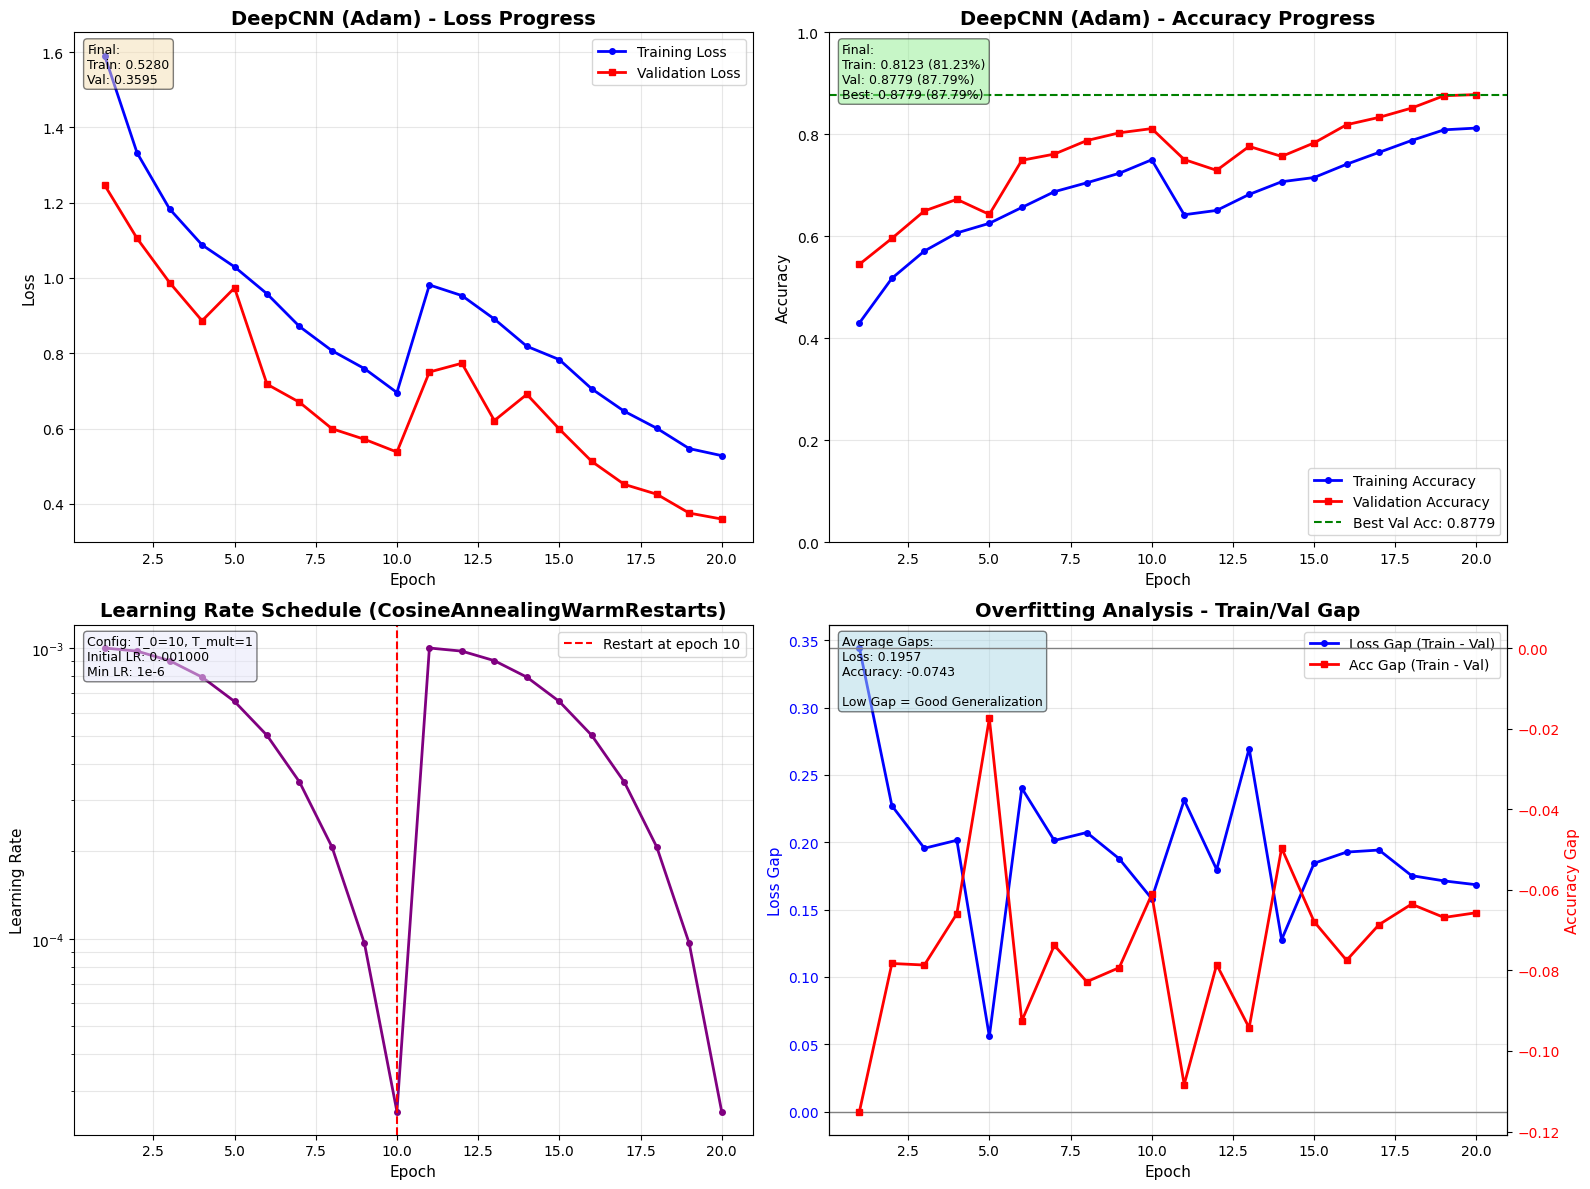

In [55]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

epochs = range(1, len(adam_history['train_loss']) + 1)

# Loss Progress
axes[0, 0].plot(epochs, adam_history['train_loss'], '-o', label='Training Loss', linewidth=2, markersize=4, color='blue')
axes[0, 0].plot(epochs, adam_history['val_loss'], '-s', label='Validation Loss', linewidth=2, markersize=4, color='red')
axes[0, 0].set_title('DeepCNN (Adam) - Loss Progress', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch', fontsize=11)
axes[0, 0].set_ylabel('Loss', fontsize=11)
axes[0, 0].legend(loc='upper right')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].text(0.02, 0.98, f'Final:\nTrain: {adam_history["train_loss"][-1]:.4f}\nVal: {adam_history["val_loss"][-1]:.4f}',
                transform=axes[0, 0].transAxes, fontsize=9, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Accuracy Progress
axes[0, 1].plot(epochs, adam_history['train_acc'], '-o', label='Training Accuracy', linewidth=2, markersize=4, color='blue')
axes[0, 1].plot(epochs, adam_history['val_acc'], '-s', label='Validation Accuracy', linewidth=2, markersize=4, color='red')
axes[0, 1].axhline(y=max(adam_history['val_acc']), color='green', linestyle='--', linewidth=1.5, 
                   label=f'Best Val Acc: {max(adam_history["val_acc"]):.4f}')
axes[0, 1].set_title('DeepCNN (Adam) - Accuracy Progress', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch', fontsize=11)
axes[0, 1].set_ylabel('Accuracy', fontsize=11)
axes[0, 1].legend(loc='lower right')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_ylim([0, 1])
axes[0, 1].text(0.02, 0.98, f'Final:\nTrain: {adam_history["train_acc"][-1]:.4f} ({adam_history["train_acc"][-1]*100:.2f}%)\nVal: {adam_history["val_acc"][-1]:.4f} ({adam_history["val_acc"][-1]*100:.2f}%)\nBest: {max(adam_history["val_acc"]):.4f} ({max(adam_history["val_acc"])*100:.2f}%)',
                transform=axes[0, 1].transAxes, fontsize=9, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))

# Learning Rate Schedule
axes[1, 0].plot(epochs, adam_history['learning_rates'], '-o', linewidth=2, markersize=4, color='purple')
axes[1, 0].set_title('Learning Rate Schedule (CosineAnnealingWarmRestarts)', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Epoch', fontsize=11)
axes[1, 0].set_ylabel('Learning Rate', fontsize=11)
axes[1, 0].set_yscale('log')
axes[1, 0].grid(True, alpha=0.3, which='both')
axes[1, 0].axvline(x=10, color='red', linestyle='--', linewidth=1.5, label='Restart at epoch 10')
axes[1, 0].legend()
axes[1, 0].text(0.02, 0.98, f'Config: T_0=10, T_mult=1\nInitial LR: {adam_history["learning_rates"][0]:.6f}\nMin LR: 1e-6',
                transform=axes[1, 0].transAxes, fontsize=9, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='lavender', alpha=0.5))

# Overfitting Analysis - Train/Val Gap
loss_gap = [train - val for train, val in zip(adam_history['train_loss'], adam_history['val_loss'])]
acc_gap = [train - val for train, val in zip(adam_history['train_acc'], adam_history['val_acc'])]

ax_gap = axes[1, 1]
ax_gap.plot(epochs, loss_gap, '-o', label='Loss Gap (Train - Val)', linewidth=2, markersize=4, color='blue')
ax_gap.set_xlabel('Epoch', fontsize=11)
ax_gap.set_ylabel('Loss Gap', fontsize=11, color='blue')
ax_gap.tick_params(axis='y', labelcolor='blue')
ax_gap.grid(True, alpha=0.3)
ax_gap.axhline(y=0, color='gray', linestyle='-', linewidth=1)

ax_gap2 = ax_gap.twinx()
ax_gap2.plot(epochs, acc_gap, '-s', label='Acc Gap (Train - Val)', linewidth=2, markersize=4, color='red')
ax_gap2.set_ylabel('Accuracy Gap', fontsize=11, color='red')
ax_gap2.tick_params(axis='y', labelcolor='red')
ax_gap2.axhline(y=0, color='gray', linestyle='-', linewidth=1)

axes[1, 1].set_title('Overfitting Analysis - Train/Val Gap', fontsize=14, fontweight='bold')
avg_loss_gap = np.mean(loss_gap)
avg_acc_gap = np.mean(acc_gap)
axes[1, 1].text(0.02, 0.98, f'Average Gaps:\nLoss: {avg_loss_gap:.4f}\nAccuracy: {avg_acc_gap:.4f}\n\nLow Gap = Good Generalization',
                transform=axes[1, 1].transAxes, fontsize=9, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

lines1, labels1 = ax_gap.get_legend_handles_labels()
lines2, labels2 = ax_gap2.get_legend_handles_labels()
ax_gap.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(PART1_DIR, 'adam_training_analysis.png'), dpi=300, bbox_inches='tight')
print(f"Plot saved to {os.path.join(PART1_DIR, 'adam_training_analysis.png')}")
plt.show()

## 12. Model Evaluation on Test Set

In [56]:
import torch
import numpy as np
import os
import time

def evaluate_model(model, test_loader, criterion, device):
    """Evaluate the model with clean progress and readable summary."""
    
    model.eval()
    test_loss = 0.0
    all_predictions, all_labels = [], []
    
    total_batches = len(test_loader)
    total_samples = len(test_loader.dataset)
    
    print(f"Starting evaluation on {total_samples:,} samples ({total_batches} batches)...")
    
    start_time = time.time()
    
    with torch.no_grad():
        for batch_idx, (inputs, labels) in enumerate(test_loader, start=1):
            inputs, labels = inputs.to(device), labels.to(device)
            
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * inputs.size(0)

            _, predicted = torch.max(outputs, 1)
            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
            # Progress update every 10 batches
            if batch_idx % 10 == 0 or batch_idx == total_batches:
                elapsed = time.time() - start_time
                progress = batch_idx / total_batches
                eta = (elapsed / batch_idx) * (total_batches - batch_idx)
                
                bar_length = 30
                filled = int(progress * bar_length)
                bar = "#" * filled + "-" * (bar_length - filled)
                
                print(f"\r[{bar}] {progress*100:5.1f}% | "
                      f"Batch {batch_idx}/{total_batches} | "
                      f"ETA: {eta:5.1f}s", end='')
    
    print()  # Move to next line after progress
    
    test_loss /= total_samples
    test_acc = np.mean(np.array(all_predictions) == np.array(all_labels))
    
    total_time = time.time() - start_time
    samples_per_sec = total_samples / total_time
    
    print(f"Evaluation completed in {total_time:.1f}s "
          f"({samples_per_sec:.1f} samples/sec)")
    
    return test_loss, test_acc, all_predictions, all_labels


# Load and evaluate the best model
best_model_path = os.path.join(MODELS_DIR, 'best_model_WasteCustom_Adam.pth')
print(f"Loading best model from: {best_model_path}")

best_model = WasteCustom(num_classes=NUM_CLASSES).to(DEVICE)
best_model.load_state_dict(torch.load(best_model_path))

# Run evaluation
test_loss, test_acc, predictions, true_labels = evaluate_model(best_model, test_loader, criterion, DEVICE)

# Final summary
correct = np.sum(np.array(predictions) == np.array(true_labels))
incorrect = len(true_labels) - correct

print("Test Set Results")
print(f"Test Loss             : {test_loss:.4f}")
print(f"Test Accuracy         : {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Total Test Samples    : {len(true_labels)}")
print(f"Correct Predictions   : {correct}")
print(f"Misclassified Samples : {incorrect}")

Loading best model from: results\models\best_model_WasteCustom_Adam.pth
Starting evaluation on 1,338 samples (42 batches)...
[##############################] 100.0% | Batch 42/42 | ETA:   0.0s
Evaluation completed in 9.4s (142.0 samples/sec)
Test Set Results
Test Loss             : 0.3530
Test Accuracy         : 0.8834 (88.34%)
Total Test Samples    : 1338
Correct Predictions   : 1182
Misclassified Samples : 156


## 13. Confusion Matrix

Confusion matrix saved to results\part1\confusion_matrix_adam.png


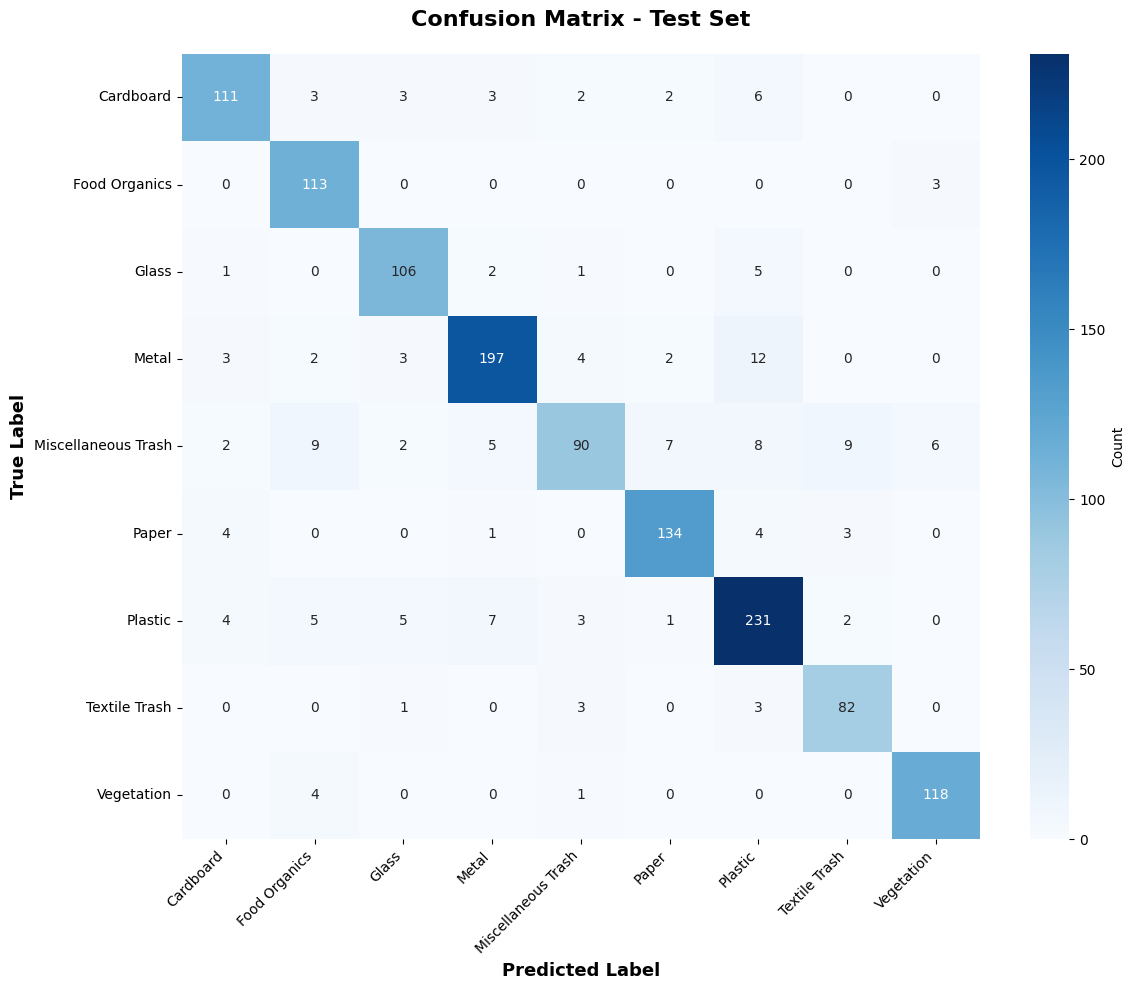

CONFUSION MATRIX ANALYSIS
Cardboard                : 111/130 correct (85.38%)
Food Organics            : 113/116 correct (97.41%)
Glass                    : 106/115 correct (92.17%)
Metal                    : 197/223 correct (88.34%)
Miscellaneous Trash      :  90/138 correct (65.22%)
Paper                    : 134/146 correct (91.78%)
Plastic                  : 231/258 correct (89.53%)
Textile Trash            :  82/ 89 correct (92.13%)
Vegetation               : 118/123 correct (95.93%)


In [57]:
cm = confusion_matrix(true_labels, predictions)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix - Test Set', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Predicted Label', fontsize=13, fontweight='bold')
plt.ylabel('True Label', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(PART1_DIR, 'confusion_matrix_adam.png'), dpi=300, bbox_inches='tight')
print(f"Confusion matrix saved to {os.path.join(PART1_DIR, 'confusion_matrix_adam.png')}")
plt.show()


print('CONFUSION MATRIX ANALYSIS')

for i, cls in enumerate(class_names):
    total = cm[i].sum()
    correct = cm[i, i]
    accuracy = correct / total if total > 0 else 0
    print(f'{cls:25s}: {correct:3d}/{total:3d} correct ({accuracy*100:5.2f}%)')

## 14. Classification Report

In [58]:
print('='*70)
print('CLASSIFICATION REPORT')
print('='*70)
print(classification_report(true_labels, predictions, target_names=class_names, digits=4))

from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(true_labels, predictions, average=None)

metrics_df = {
    'Class': class_names,
    'Precision': [f'{p:.4f}' for p in precision],
    'Recall': [f'{r:.4f}' for r in recall],
    'F1-Score': [f'{f:.4f}' for f in f1],
    'Support': support
}

print('\n' + '='*70)
print('PER-CLASS METRICS SUMMARY')
print('='*70)
for i in range(len(class_names)):
    print(f'{metrics_df["Class"][i]:25s} | P: {metrics_df["Precision"][i]} | R: {metrics_df["Recall"][i]} | F1: {metrics_df["F1-Score"][i]} | Support: {metrics_df["Support"][i]:3d}')
print('='*70)

CLASSIFICATION REPORT
                     precision    recall  f1-score   support

          Cardboard     0.8880    0.8538    0.8706       130
      Food Organics     0.8309    0.9741    0.8968       116
              Glass     0.8833    0.9217    0.9021       115
              Metal     0.9163    0.8834    0.8995       223
Miscellaneous Trash     0.8654    0.6522    0.7438       138
              Paper     0.9178    0.9178    0.9178       146
            Plastic     0.8587    0.8953    0.8767       258
      Textile Trash     0.8542    0.9213    0.8865        89
         Vegetation     0.9291    0.9593    0.9440       123

           accuracy                         0.8834      1338
          macro avg     0.8826    0.8866    0.8820      1338
       weighted avg     0.8842    0.8834    0.8815      1338


PER-CLASS METRICS SUMMARY
Cardboard                 | P: 0.8880 | R: 0.8538 | F1: 0.8706 | Support: 130
Food Organics             | P: 0.8309 | R: 0.9741 | F1: 0.8968 | Support: 116

## 15. Performance Metrics Visualization

Performance metrics plot saved to results\part1\performance_metrics.png


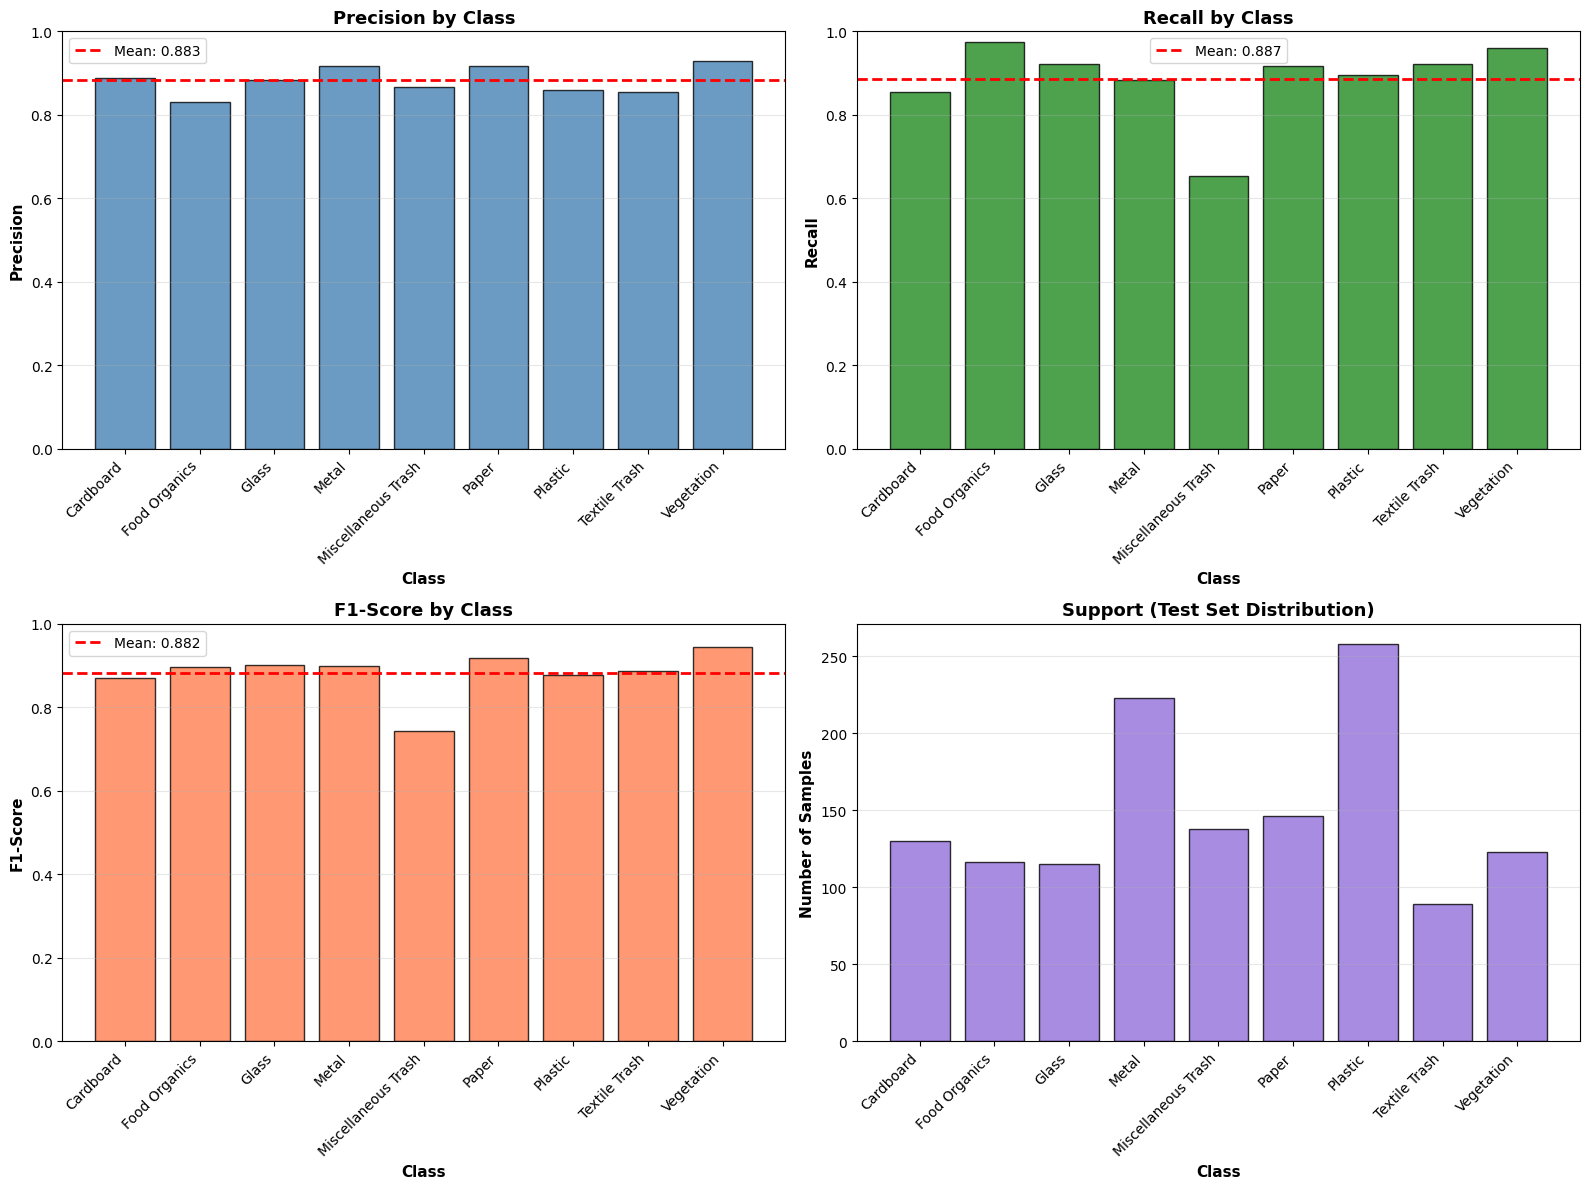

In [59]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

x_pos = np.arange(len(class_names))

# Precision
axes[0, 0].bar(x_pos, precision, color='steelblue', alpha=0.8, edgecolor='black')
axes[0, 0].set_xlabel('Class', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Precision', fontsize=11, fontweight='bold')
axes[0, 0].set_title('Precision by Class', fontsize=13, fontweight='bold')
axes[0, 0].set_xticks(x_pos)
axes[0, 0].set_xticklabels(class_names, rotation=45, ha='right')
axes[0, 0].set_ylim([0, 1])
axes[0, 0].grid(axis='y', alpha=0.3)
axes[0, 0].axhline(y=np.mean(precision), color='r', linestyle='--', linewidth=2, label=f'Mean: {np.mean(precision):.3f}')
axes[0, 0].legend()

# Recall
axes[0, 1].bar(x_pos, recall, color='forestgreen', alpha=0.8, edgecolor='black')
axes[0, 1].set_xlabel('Class', fontsize=11, fontweight='bold')
axes[0, 1].set_ylabel('Recall', fontsize=11, fontweight='bold')
axes[0, 1].set_title('Recall by Class', fontsize=13, fontweight='bold')
axes[0, 1].set_xticks(x_pos)
axes[0, 1].set_xticklabels(class_names, rotation=45, ha='right')
axes[0, 1].set_ylim([0, 1])
axes[0, 1].grid(axis='y', alpha=0.3)
axes[0, 1].axhline(y=np.mean(recall), color='r', linestyle='--', linewidth=2, label=f'Mean: {np.mean(recall):.3f}')
axes[0, 1].legend()

# F1-Score
axes[1, 0].bar(x_pos, f1, color='coral', alpha=0.8, edgecolor='black')
axes[1, 0].set_xlabel('Class', fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('F1-Score', fontsize=11, fontweight='bold')
axes[1, 0].set_title('F1-Score by Class', fontsize=13, fontweight='bold')
axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(class_names, rotation=45, ha='right')
axes[1, 0].set_ylim([0, 1])
axes[1, 0].grid(axis='y', alpha=0.3)
axes[1, 0].axhline(y=np.mean(f1), color='r', linestyle='--', linewidth=2, label=f'Mean: {np.mean(f1):.3f}')
axes[1, 0].legend()

# Support (Test Set Distribution)
axes[1, 1].bar(x_pos, support, color='mediumpurple', alpha=0.8, edgecolor='black')
axes[1, 1].set_xlabel('Class', fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('Number of Samples', fontsize=11, fontweight='bold')
axes[1, 1].set_title('Support (Test Set Distribution)', fontsize=13, fontweight='bold')
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(class_names, rotation=45, ha='right')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(PART1_DIR, 'performance_metrics.png'), dpi=300, bbox_inches='tight')
print(f"Performance metrics plot saved to {os.path.join(PART1_DIR, 'performance_metrics.png')}")
plt.show()

## 16. Model Performance Analysis

In [60]:
print('='*70)
print('MODEL PERFORMANCE ANALYSIS')
print('='*70)

print('\n1. OVERALL METRICS:')
print('-' * 70)
print(f'   Test Accuracy:           {test_acc:.4f} ({test_acc*100:.2f}%)')
print(f'   Macro Average Precision: {np.mean(precision):.4f}')
print(f'   Macro Average Recall:    {np.mean(recall):.4f}')
print(f'   Macro Average F1-Score:  {np.mean(f1):.4f}')

print('\n2. BEST PERFORMING CLASSES:')
print('-' * 70)
best_f1_idx = np.argsort(f1)[-3:][::-1]
for idx in best_f1_idx:
    print(f'   {class_names[idx]:25s} - F1: {f1[idx]:.4f}, Precision: {precision[idx]:.4f}, Recall: {recall[idx]:.4f}')

print('\n3. WORST PERFORMING CLASSES:')
print('-' * 70)
worst_f1_idx = np.argsort(f1)[:3]
for idx in worst_f1_idx:
    print(f'   {class_names[idx]:25s} - F1: {f1[idx]:.4f}, Precision: {precision[idx]:.4f}, Recall: {recall[idx]:.4f}')

print('\n4. MISCLASSIFICATION ANALYSIS:')
print('-' * 70)
misclassifications = []
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i, j] > 0:
            misclassifications.append((class_names[i], class_names[j], cm[i, j]))

misclassifications.sort(key=lambda x: x[2], reverse=True)
print('   Top 5 Most Common Misclassifications:')
for true_cls, pred_cls, count in misclassifications[:5]:
    print(f'   {true_cls:25s} -> {pred_cls:25s}: {count:3d} times')

print('\n5. TRAINING CONVERGENCE:')
print('-' * 70)
print(f'   Initial Training Accuracy:   {adam_history["train_acc"][0]:.4f}')
print(f'   Final Training Accuracy:     {adam_history["train_acc"][-1]:.4f}')
print(f'   Training Improvement:        {(adam_history["train_acc"][-1] - adam_history["train_acc"][0]):.4f}')
print(f'   Initial Validation Accuracy: {adam_history["val_acc"][0]:.4f}')
print(f'   Final Validation Accuracy:   {adam_history["val_acc"][-1]:.4f}')
print(f'   Best Validation Accuracy:    {max(adam_history["val_acc"]):.4f} (Epoch {adam_history["val_acc"].index(max(adam_history["val_acc"]))+1})')

overfitting_gap = adam_history["train_acc"][-1] - adam_history["val_acc"][-1]
print(f'\n6. OVERFITTING ANALYSIS:')
print('-' * 70)
print(f'   Train-Validation Gap:        {overfitting_gap:.4f}')
if overfitting_gap < 0.1:
    print('   Status: Model generalizes well (minimal overfitting)')
elif overfitting_gap < 0.15:
    print('   Status: Slight overfitting detected')
else:
    print('   Status: Significant overfitting - consider regularization')

print('\n' + '='*70)

MODEL PERFORMANCE ANALYSIS

1. OVERALL METRICS:
----------------------------------------------------------------------
   Test Accuracy:           0.8834 (88.34%)
   Macro Average Precision: 0.8826
   Macro Average Recall:    0.8866
   Macro Average F1-Score:  0.8820

2. BEST PERFORMING CLASSES:
----------------------------------------------------------------------
   Vegetation                - F1: 0.9440, Precision: 0.9291, Recall: 0.9593
   Paper                     - F1: 0.9178, Precision: 0.9178, Recall: 0.9178
   Glass                     - F1: 0.9021, Precision: 0.8833, Recall: 0.9217

3. WORST PERFORMING CLASSES:
----------------------------------------------------------------------
   Miscellaneous Trash       - F1: 0.7438, Precision: 0.8654, Recall: 0.6522
   Cardboard                 - F1: 0.8706, Precision: 0.8880, Recall: 0.8538
   Plastic                   - F1: 0.8767, Precision: 0.8587, Recall: 0.8953

4. MISCLASSIFICATION ANALYSIS:
-------------------------------------

## 17. Sample Predictions Visualization

Sample predictions saved to results\part1\sample_predictions.png


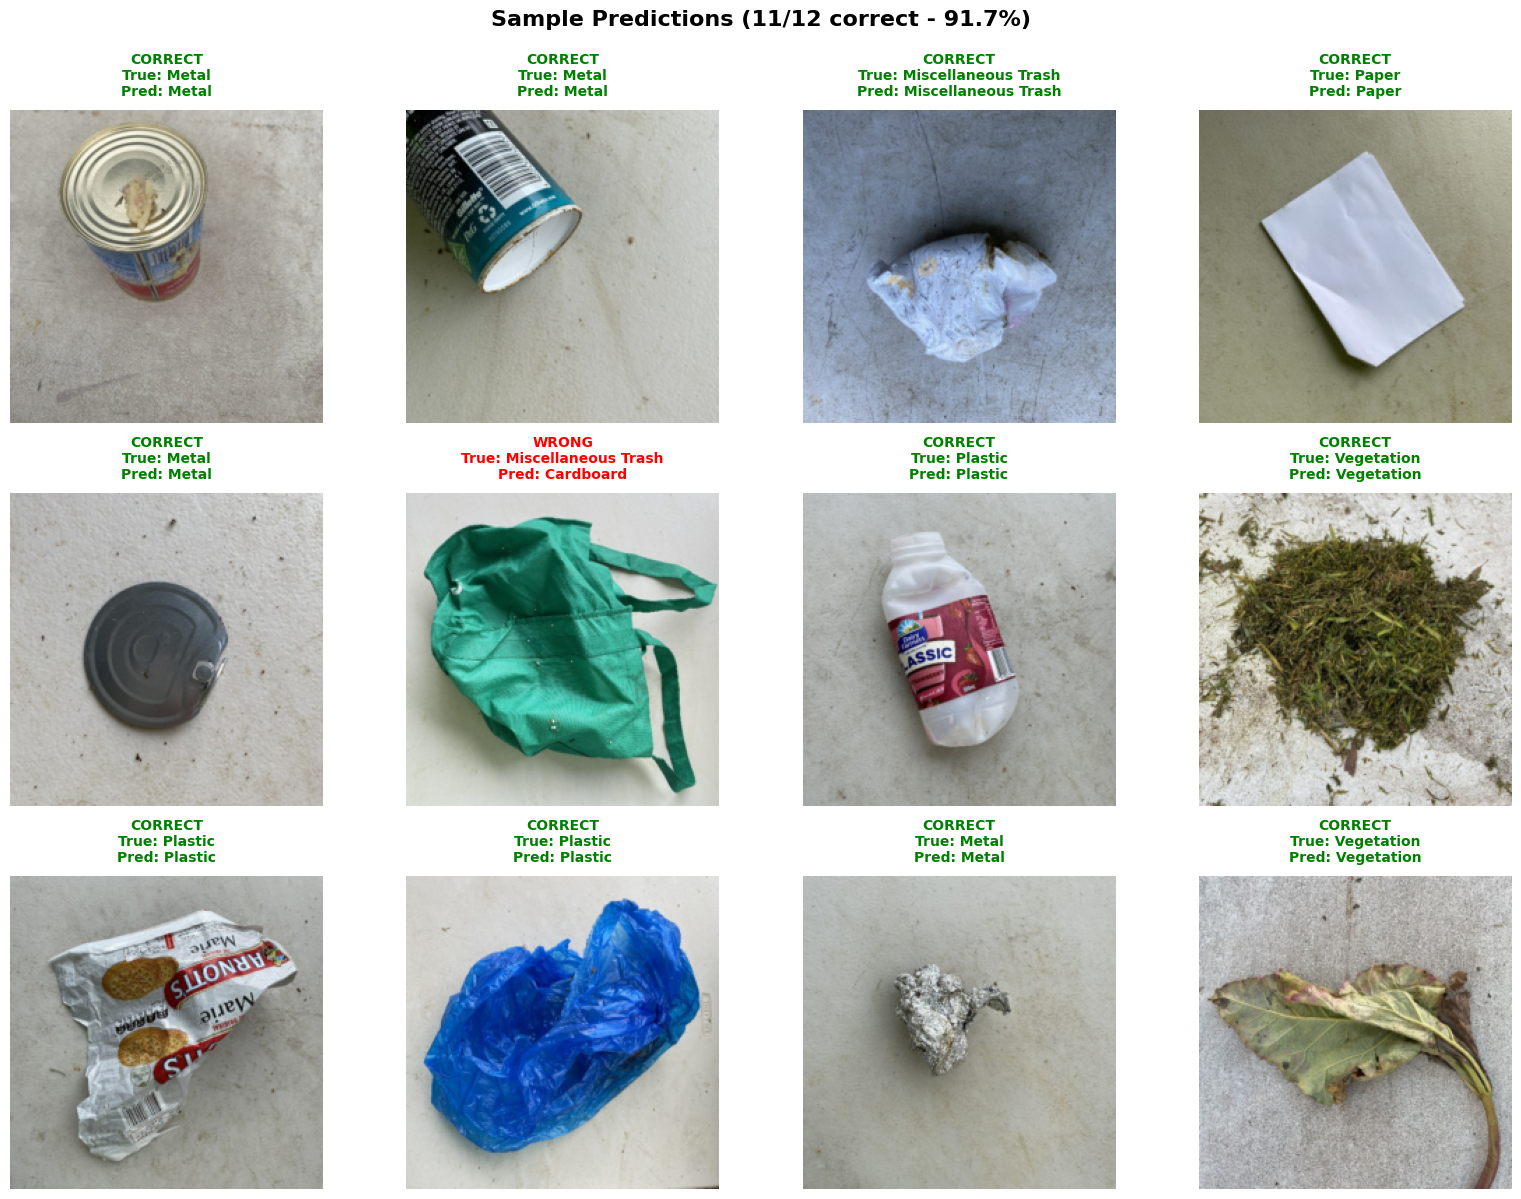

In [61]:
import random

def denormalize(tensor):
    """Denormalize image tensor for visualization"""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    tensor = tensor * std + mean
    tensor = torch.clamp(tensor, 0, 1)
    return tensor

def show_predictions(model, test_dataset, class_names, device, num_samples=12):
    model.eval()
    indices = random.sample(range(len(test_dataset)), num_samples)

    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    axes = axes.ravel()

    correct_count = 0

    with torch.no_grad():
        for i, idx in enumerate(indices):
            image, true_label = test_dataset[idx]
            image_input = image.unsqueeze(0).to(device)

            output = model(image_input)
            _, predicted = torch.max(output, 1)
            pred_label = predicted.item()

            img_display = denormalize(image).permute(1, 2, 0).cpu().numpy()

            axes[i].imshow(img_display)
            axes[i].axis('off')

            is_correct = (pred_label == true_label)
            if is_correct:
                correct_count += 1
                color = 'green'
                status = 'CORRECT'
            else:
                color = 'red'
                status = 'WRONG'

            axes[i].set_title(f'{status}\nTrue: {class_names[true_label]}\nPred: {class_names[pred_label]}', 
                            color=color, fontsize=10, fontweight='bold', pad=10)

    plt.suptitle(f'Sample Predictions ({correct_count}/{num_samples} correct - {correct_count/num_samples*100:.1f}%)',
                 fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.savefig(os.path.join(PART1_DIR, 'sample_predictions.png'), dpi=300, bbox_inches='tight')
    print(f"Sample predictions saved to {os.path.join(PART1_DIR, 'sample_predictions.png')}")
    plt.show()

# Get the test dataset (without DataLoader)
from torchvision import datasets, transforms
test_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

test_dataset = datasets.ImageFolder(
    root=os.path.join(SPLIT_DATA_DIR, 'test'),
    transform=test_transform
)

show_predictions(best_model, test_dataset, class_names, DEVICE, num_samples=12)

# Part 2: Transfer Learning with State-of-the-Art Models

In this part, we evaluate two state-of-the-art pre-trained models for waste classification using transfer learning:

1. **ResNet-50**: A deep residual network with skip connections
2. **EfficientNet-B0**: An efficient architecture optimized using compound scaling

We will:
- Load pre-trained models from ImageNet
- Fine-tune them on our waste classification dataset
- Compare their performance with our custom CNN from Part 1
- Analyze trade-offs, advantages, and limitations

## 18. Install Required Packages for Transfer Learning

In [43]:
# Install timm (PyTorch Image Models) for EfficientNet
! pip install timm -q

## 19. Helper Functions for Transfer Learning

In [44]:
import timm
from torchvision import models

# Create directory for Part 2 results
PART2_DIR = os.path.join(RESULTS_DIR, 'part2')
os.makedirs(PART2_DIR, exist_ok=True)

def train_one_epoch_optimized(model, train_loader, criterion, optimizer, device):
    """Train for one epoch without verbose progress bars"""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def validate_optimized(model, val_loader, criterion, device):
    """Validate the model without verbose progress bars"""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def train_with_early_stopping(model, train_loader, val_loader, criterion, optimizer, 
                               scheduler, device, num_epochs, patience=3, min_delta=0.001,
                               model_name='model'):
    """Train model with early stopping"""
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': [],
        'lr': []
    }
    
    best_val_loss = float('inf')
    best_model_wts = None
    patience_counter = 0
    
    print(f"\nTraining {model_name}...")
    print("=" * 60)
    
    for epoch in range(num_epochs):
        # Training phase
        train_loss, train_acc = train_one_epoch_optimized(model, train_loader, criterion, optimizer, device)
        
        # Validation phase
        val_loss, val_acc = validate_optimized(model, val_loader, criterion, device)
        
        # Learning rate scheduling
        if scheduler is not None:
            scheduler.step()
            current_lr = optimizer.param_groups[0]['lr']
        else:
            current_lr = optimizer.param_groups[0]['lr']
        
        # Save history
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['lr'].append(current_lr)
        
        # Print progress
        print(f"Epoch {epoch+1:2d}/{num_epochs} | "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | "
              f"LR: {current_lr:.6f}")
        
        # Early stopping check
        if val_loss < (best_val_loss - min_delta):
            best_val_loss = val_loss
            best_model_wts = model.state_dict().copy()
            patience_counter = 0
            print(f"  → New best model! Val Loss improved to {val_loss:.4f}")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"\nEarly stopping triggered after {epoch+1} epochs")
                break
    
    # Load best model weights
    if best_model_wts is not None:
        model.load_state_dict(best_model_wts)
    
    print("=" * 60)
    print(f"Training completed! Best Val Loss: {best_val_loss:.4f}\n")
    
    return model, history

print("Helper functions defined successfully!")

Helper functions defined successfully!


## 20. SOTA Model 1: ResNet-50 with Transfer Learning

### Model Selection Justification: ResNet-50 - "The Fundamental Breakthrough"

**Why ResNet-50?**

1. **Residual Connections:** ResNet introduced skip connections that allow gradients to flow directly through the network, solving the vanishing gradient problem and enabling training of very deep networks (50+ layers).

2. **Strong ImageNet Performance:** Pre-trained on ImageNet (1.2M images, 1000 classes), ResNet-50 has learned robust, generalizable features that transfer well to various computer vision tasks.

3. **Balanced Architecture:** With 50 layers, it offers a good balance between model capacity and computational efficiency, making it suitable for transfer learning.

4. **Wide Adoption:** Extensively used in research and industry, making it a reliable baseline for comparison.

5. **Feature Hierarchy:** The deep architecture learns hierarchical features from low-level edges to high-level semantic concepts, ideal for waste classification.

In [9]:
print("Initializing ResNet-50...")

# Load pre-trained ResNet-50
resnet50 = models.resnet50(pretrained=True)

# Freeze early layers (conv1, bn1, layer1, layer2)
for param in resnet50.conv1.parameters():
    param.requires_grad = False
for param in resnet50.bn1.parameters():
    param.requires_grad = False
for param in resnet50.layer1.parameters():
    param.requires_grad = False
for param in resnet50.layer2.parameters():
    param.requires_grad = False

# Replace final fully connected layer
num_ftrs = resnet50.fc.in_features
resnet50.fc = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(num_ftrs, NUM_CLASSES)
)

resnet50 = resnet50.to(DEVICE)

# Count trainable parameters
total_params = sum(p.numel() for p in resnet50.parameters())
trainable_params = sum(p.numel() for p in resnet50.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

# Define loss, optimizer, and scheduler for ResNet-50
criterion_resnet = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_resnet = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, resnet50.parameters()),
    lr=1e-4,
    weight_decay=0.05
)
scheduler_resnet = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_resnet,
    T_max=10,
    eta_min=1e-6
)

# Train ResNet-50
resnet50, resnet_history = train_with_early_stopping(
    model=resnet50,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion_resnet,
    optimizer=optimizer_resnet,
    scheduler=scheduler_resnet,
    device=DEVICE,
    num_epochs=10,
    patience=3,
    min_delta=0.001,
    model_name='ResNet-50'
)

# Save the model
resnet_model_path = os.path.join(MODELS_DIR, 'best_model_ResNet50_Adam.pth')
torch.save(resnet50.state_dict(), resnet_model_path)
print(f"✓ Model saved to {resnet_model_path}")

Initializing ResNet-50...
Total parameters: 23,526,473
Trainable parameters: 22,081,545
Frozen parameters: 1,444,928

Training ResNet-50...
Total parameters: 23,526,473
Trainable parameters: 22,081,545
Frozen parameters: 1,444,928

Training ResNet-50...
Epoch  1/10 | Train Loss: 1.1520 | Train Acc: 0.7176 | Val Loss: 0.7715 | Val Acc: 0.9007 | LR: 0.000098
  → New best model! Val Loss improved to 0.7715
Epoch  1/10 | Train Loss: 1.1520 | Train Acc: 0.7176 | Val Loss: 0.7715 | Val Acc: 0.9007 | LR: 0.000098
  → New best model! Val Loss improved to 0.7715
Epoch  2/10 | Train Loss: 0.7606 | Train Acc: 0.9030 | Val Loss: 0.6824 | Val Acc: 0.9348 | LR: 0.000091
  → New best model! Val Loss improved to 0.6824
Epoch  2/10 | Train Loss: 0.7606 | Train Acc: 0.9030 | Val Loss: 0.6824 | Val Acc: 0.9348 | LR: 0.000091
  → New best model! Val Loss improved to 0.6824
Epoch  3/10 | Train Loss: 0.6541 | Train Acc: 0.9479 | Val Loss: 0.5941 | Val Acc: 0.9727 | LR: 0.000080
  → New best model! Val Loss 

### ResNet-50 Training Analysis

✓ ResNet-50 training analysis saved to results\part2/resnet50_training_analysis.png


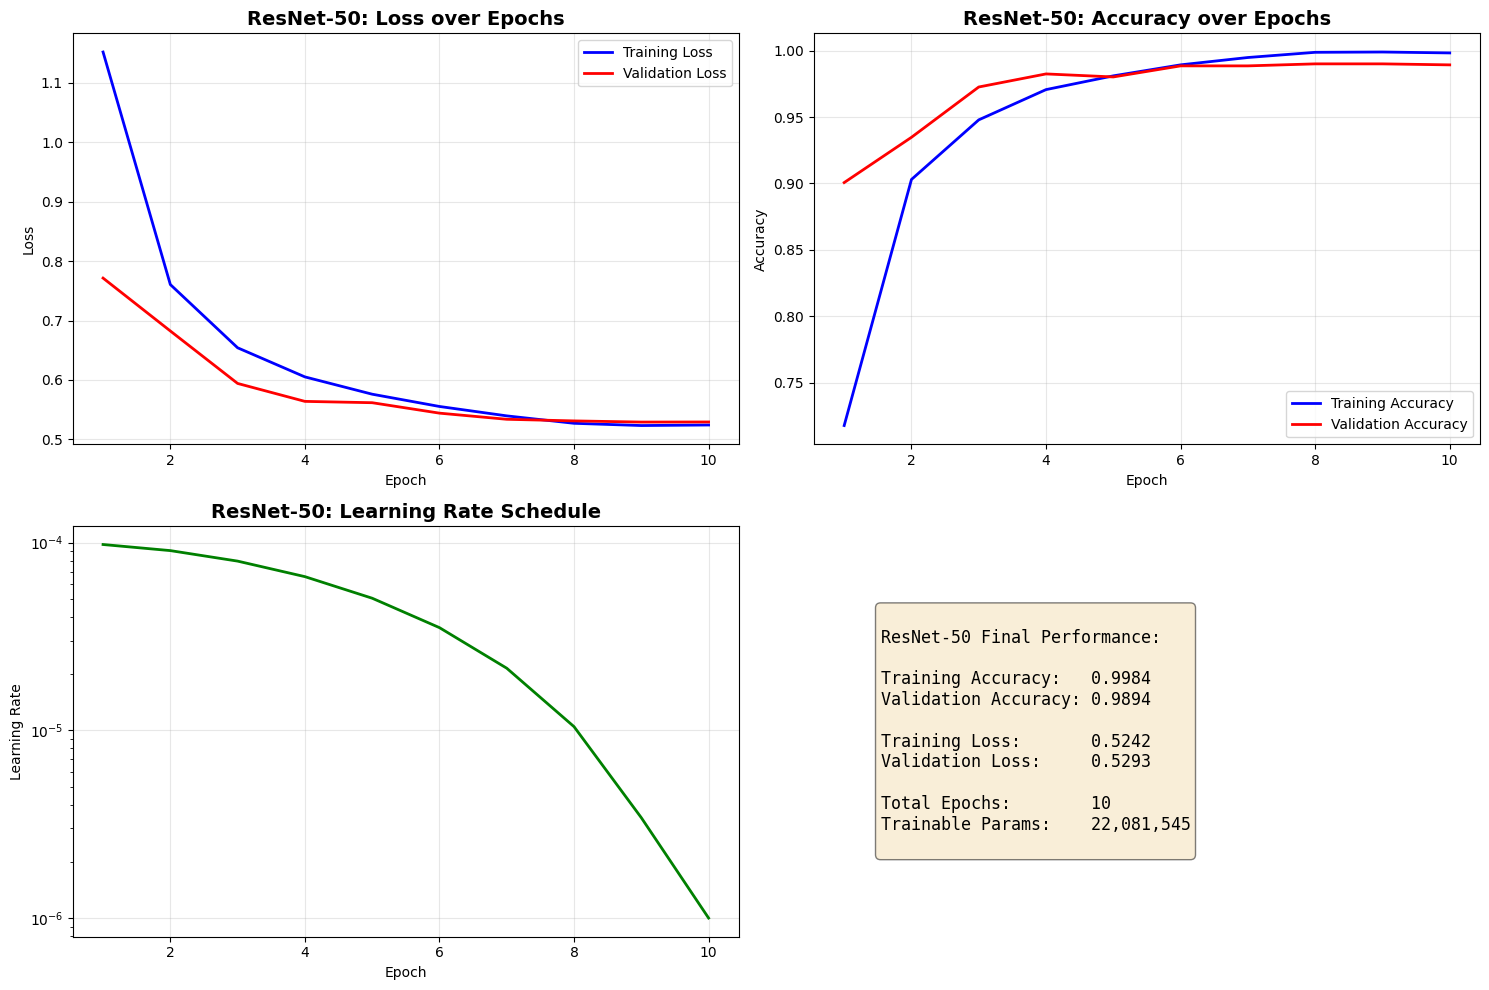

In [10]:
# Plot ResNet-50 training results
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

epochs_resnet = range(1, len(resnet_history['train_loss']) + 1)

# Training Loss
axes[0, 0].plot(epochs_resnet, resnet_history['train_loss'], 'b-', label='Training Loss', linewidth=2)
axes[0, 0].plot(epochs_resnet, resnet_history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
axes[0, 0].set_title('ResNet-50: Loss over Epochs', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Training Accuracy
axes[0, 1].plot(epochs_resnet, resnet_history['train_acc'], 'b-', label='Training Accuracy', linewidth=2)
axes[0, 1].plot(epochs_resnet, resnet_history['val_acc'], 'r-', label='Validation Accuracy', linewidth=2)
axes[0, 1].set_title('ResNet-50: Accuracy over Epochs', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Learning Rate
axes[1, 0].plot(epochs_resnet, resnet_history['lr'], 'g-', linewidth=2)
axes[1, 0].set_title('ResNet-50: Learning Rate Schedule', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Learning Rate')
axes[1, 0].set_yscale('log')
axes[1, 0].grid(True, alpha=0.3)

# Performance Summary
final_train_acc = resnet_history['train_acc'][-1]
final_val_acc = resnet_history['val_acc'][-1]
final_train_loss = resnet_history['train_loss'][-1]
final_val_loss = resnet_history['val_loss'][-1]

summary_text = f"""
ResNet-50 Final Performance:

Training Accuracy:   {final_train_acc:.4f}
Validation Accuracy: {final_val_acc:.4f}

Training Loss:       {final_train_loss:.4f}
Validation Loss:     {final_val_loss:.4f}

Total Epochs:        {len(epochs_resnet)}
Trainable Params:    {trainable_params:,}
"""

axes[1, 1].text(0.1, 0.5, summary_text, fontsize=12, family='monospace',
                verticalalignment='center', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
axes[1, 1].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(PART2_DIR, 'resnet50_training_analysis.png'), dpi=300, bbox_inches='tight')
print(f"✓ ResNet-50 training analysis saved to {PART2_DIR}/resnet50_training_analysis.png")
plt.show()

## 21. SOTA Model 2: EfficientNet-B0 with Transfer Learning

### Model Selection Justification: EfficientNet-B0 - "The Efficiency Revolution"

**Why EfficientNet-B0?**

1. **Compound Scaling:** EfficientNet uses a principled approach to scale networks uniformly across depth, width, and resolution, achieving better efficiency than conventional methods.

2. **Parameter Efficiency:** EfficientNet-B0 achieves competitive accuracy with significantly fewer parameters (~5.3M) compared to ResNet-50 (~25.6M), making it ideal for resource-constrained environments.

3. **State-of-the-Art Performance:** Despite being lightweight, EfficientNet models achieve top performance on ImageNet and transfer well to other domains.

4. **Mobile-Friendly:** The efficient architecture makes it suitable for deployment on mobile devices and edge computing scenarios.

5. **Modern Architecture:** Incorporates advanced techniques like squeeze-and-excitation blocks and optimized depthwise separable convolutions for better feature extraction.

In [11]:
# EfficientNet-B0 requires 224x224 input (can use same data loaders)
# But we'll add more aggressive augmentation for better generalization

print("Setting up data loaders for EfficientNet-B0...")

# Enhanced transforms for EfficientNet with more augmentation
efficientnet_train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

efficientnet_val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Create datasets with EfficientNet transforms
efficientnet_train_dataset = datasets.ImageFolder(
    root=os.path.join(SPLIT_DATA_DIR, 'train'),
    transform=efficientnet_train_transform
)

efficientnet_val_dataset = datasets.ImageFolder(
    root=os.path.join(SPLIT_DATA_DIR, 'validation'),
    transform=efficientnet_val_transform
)

# Create data loaders
efficientnet_train_loader = DataLoader(
    efficientnet_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

efficientnet_val_loader = DataLoader(
    efficientnet_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(f"✓ EfficientNet data loaders created")
print(f"  Training samples: {len(efficientnet_train_dataset):,}")
print(f"  Validation samples: {len(efficientnet_val_dataset):,}")

Setting up data loaders for EfficientNet-B0...
✓ EfficientNet data loaders created
  Training samples: 4,341
  Validation samples: 1,319


In [13]:
print("Initializing EfficientNet-B0...")

# Load pre-trained EfficientNet-B0 from timm
efficientnet_b0 = timm.create_model('efficientnet_b0', pretrained=True, num_classes=NUM_CLASSES)

# Freeze early layers (blocks 0-3)
for name, param in efficientnet_b0.named_parameters():
    if 'blocks.0' in name or 'blocks.1' in name or 'blocks.2' in name or 'blocks.3' in name:
        param.requires_grad = False
    if 'conv_stem' in name or 'bn1' in name:
        param.requires_grad = False

efficientnet_b0 = efficientnet_b0.to(DEVICE)

# Count trainable parameters
total_params_eff = sum(p.numel() for p in efficientnet_b0.parameters())
trainable_params_eff = sum(p.numel() for p in efficientnet_b0.parameters() if p.requires_grad)
print(f"Total parameters: {total_params_eff:,}")
print(f"Trainable parameters: {trainable_params_eff:,}")
print(f"Frozen parameters: {total_params_eff - trainable_params_eff:,}")
print(f"Parameter efficiency: {total_params_eff / 1e6:.2f}M (vs ResNet-50: {total_params / 1e6:.2f}M)")

# Define loss, optimizer, and scheduler for EfficientNet-B0
criterion_eff = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer_eff = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, efficientnet_b0.parameters()),
    lr=5e-4,
    weight_decay=0.05
)
scheduler_eff = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_eff,
    T_max=10,
    eta_min=1e-6
)

# Train EfficientNet-B0
efficientnet_b0, efficientnet_history = train_with_early_stopping(
    model=efficientnet_b0,
    train_loader=efficientnet_train_loader,
    val_loader=efficientnet_val_loader,
    criterion=criterion_eff,
    optimizer=optimizer_eff,
    scheduler=scheduler_eff,
    device=DEVICE,
    num_epochs=10,
    patience=3,
    min_delta=0.001,
    model_name='EfficientNet-B0'
)

# Save the model
efficientnet_model_path = os.path.join(MODELS_DIR, 'best_model_EfficientNetB0_Adam.pth')
torch.save(efficientnet_b0.state_dict(), efficientnet_model_path)
print(f"✓ Model saved to {efficientnet_model_path}")

Initializing EfficientNet-B0...
Total parameters: 4,019,077
Trainable parameters: 3,696,209
Frozen parameters: 322,868
Parameter efficiency: 4.02M (vs ResNet-50: 23.53M)

Training EfficientNet-B0...
Total parameters: 4,019,077
Trainable parameters: 3,696,209
Frozen parameters: 322,868
Parameter efficiency: 4.02M (vs ResNet-50: 23.53M)

Training EfficientNet-B0...
Epoch  1/10 | Train Loss: 1.3881 | Train Acc: 0.6722 | Val Loss: 0.8692 | Val Acc: 0.8681 | LR: 0.000488
  → New best model! Val Loss improved to 0.8692
Epoch  1/10 | Train Loss: 1.3881 | Train Acc: 0.6722 | Val Loss: 0.8692 | Val Acc: 0.8681 | LR: 0.000488
  → New best model! Val Loss improved to 0.8692
Epoch  2/10 | Train Loss: 0.8893 | Train Acc: 0.8493 | Val Loss: 0.7583 | Val Acc: 0.9121 | LR: 0.000452
  → New best model! Val Loss improved to 0.7583
Epoch  2/10 | Train Loss: 0.8893 | Train Acc: 0.8493 | Val Loss: 0.7583 | Val Acc: 0.9121 | LR: 0.000452
  → New best model! Val Loss improved to 0.7583
Epoch  3/10 | Train Lo

### EfficientNet-B0 Training Analysis

✓ EfficientNet-B0 training analysis saved to results\part2/efficientnet_training_analysis.png


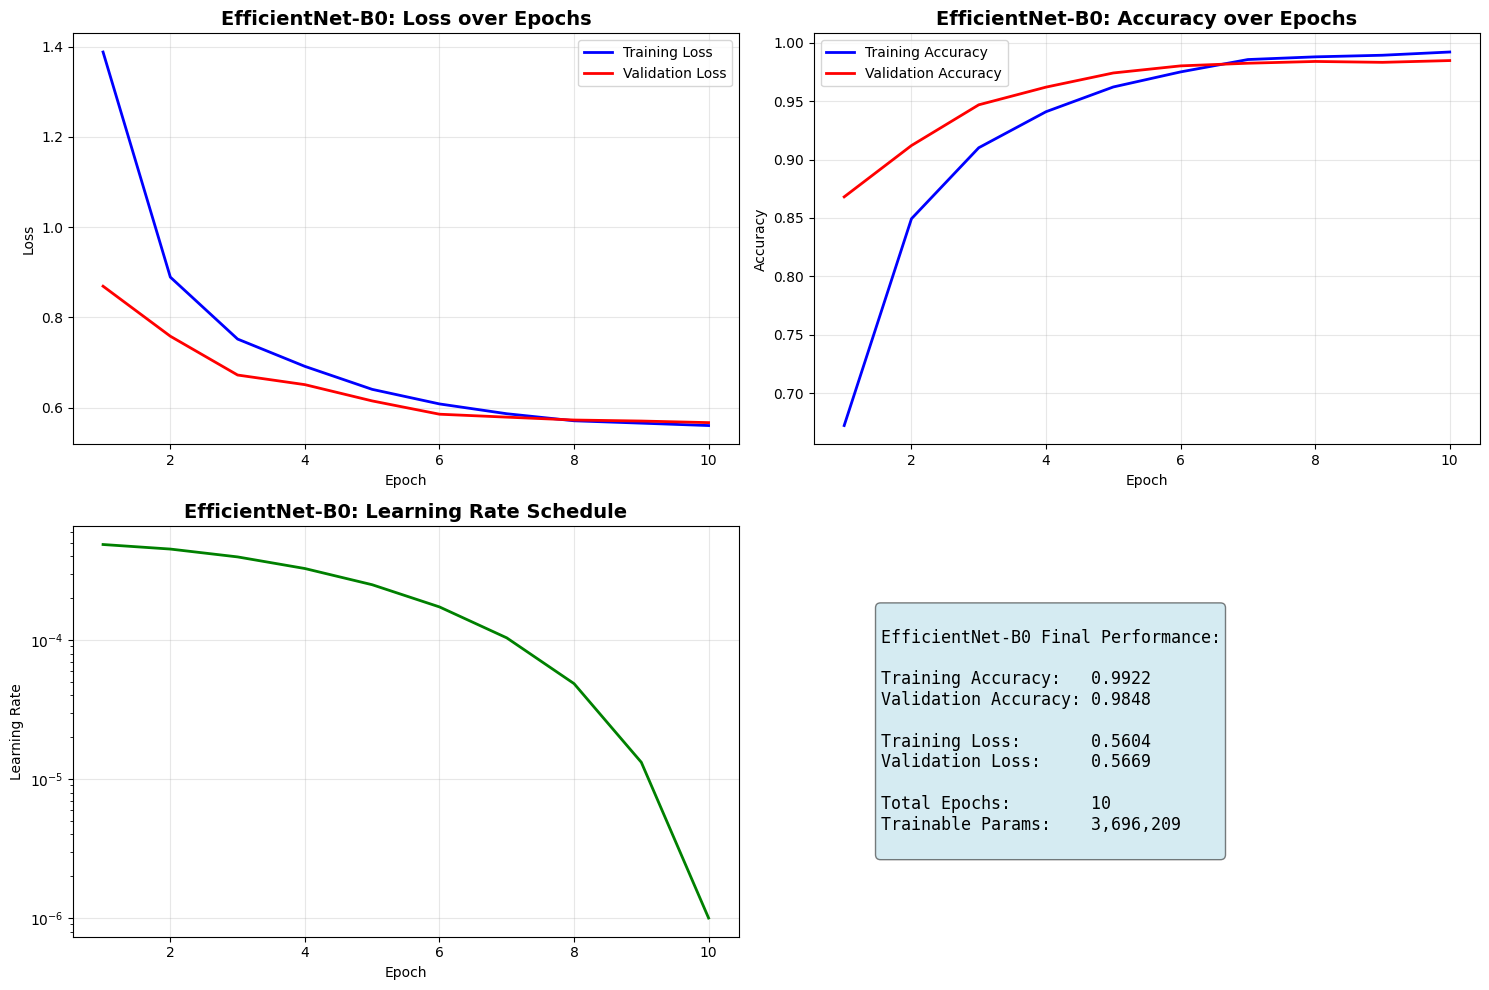

In [14]:
# Plot EfficientNet-B0 training results
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

epochs_eff = range(1, len(efficientnet_history['train_loss']) + 1)

# Training Loss
axes[0, 0].plot(epochs_eff, efficientnet_history['train_loss'], 'b-', label='Training Loss', linewidth=2)
axes[0, 0].plot(epochs_eff, efficientnet_history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
axes[0, 0].set_title('EfficientNet-B0: Loss over Epochs', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Training Accuracy
axes[0, 1].plot(epochs_eff, efficientnet_history['train_acc'], 'b-', label='Training Accuracy', linewidth=2)
axes[0, 1].plot(epochs_eff, efficientnet_history['val_acc'], 'r-', label='Validation Accuracy', linewidth=2)
axes[0, 1].set_title('EfficientNet-B0: Accuracy over Epochs', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Learning Rate
axes[1, 0].plot(epochs_eff, efficientnet_history['lr'], 'g-', linewidth=2)
axes[1, 0].set_title('EfficientNet-B0: Learning Rate Schedule', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Learning Rate')
axes[1, 0].set_yscale('log')
axes[1, 0].grid(True, alpha=0.3)

# Performance Summary
final_train_acc_eff = efficientnet_history['train_acc'][-1]
final_val_acc_eff = efficientnet_history['val_acc'][-1]
final_train_loss_eff = efficientnet_history['train_loss'][-1]
final_val_loss_eff = efficientnet_history['val_loss'][-1]

summary_text_eff = f"""
EfficientNet-B0 Final Performance:

Training Accuracy:   {final_train_acc_eff:.4f}
Validation Accuracy: {final_val_acc_eff:.4f}

Training Loss:       {final_train_loss_eff:.4f}
Validation Loss:     {final_val_loss_eff:.4f}

Total Epochs:        {len(epochs_eff)}
Trainable Params:    {trainable_params_eff:,}
"""

axes[1, 1].text(0.1, 0.5, summary_text_eff, fontsize=12, family='monospace',
                verticalalignment='center', bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))
axes[1, 1].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(PART2_DIR, 'efficientnet_training_analysis.png'), dpi=300, bbox_inches='tight')
print(f"✓ EfficientNet-B0 training analysis saved to {PART2_DIR}/efficientnet_training_analysis.png")
plt.show()

## 22. Test Set Evaluation: ResNet-50

Evaluating ResNet-50 on Test Set...

ResNet-50 Test Results:
  Test Loss:     0.5300
  Test Accuracy: 0.9888 (98.88%)
  Correct:       1323/1338

Classification Report (ResNet-50):
                     precision    recall  f1-score   support

          Cardboard       0.98      1.00      0.99       130
      Food Organics       0.98      1.00      0.99       116
              Glass       0.99      0.99      0.99       115
              Metal       0.98      0.99      0.98       223
Miscellaneous Trash       0.99      0.99      0.99       138
              Paper       0.99      1.00      1.00       146
            Plastic       0.99      0.97      0.98       258
      Textile Trash       1.00      0.99      0.99        89
         Vegetation       1.00      0.98      0.99       123

           accuracy                           0.99      1338
          macro avg       0.99      0.99      0.99      1338
       weighted avg       0.99      0.99      0.99      1338


ResNet-50 Test Results

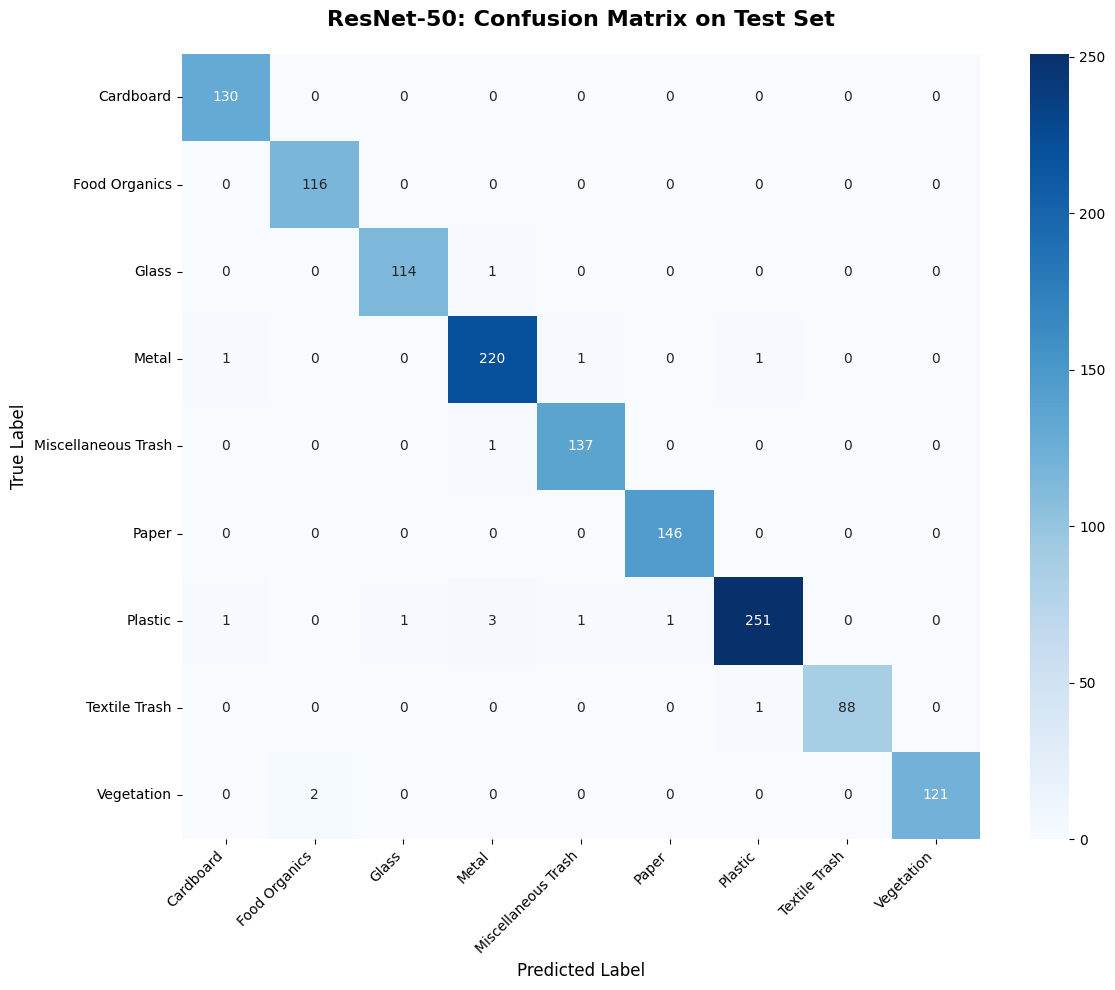

In [45]:
print("Evaluating ResNet-50 on Test Set...")
print("=" * 60)

# Evaluate on test set
resnet50.eval()
all_preds_resnet = []
all_labels_resnet = []
test_loss_resnet = 0.0
correct_resnet = 0
total_resnet = 0

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = resnet50(inputs)
        loss = criterion_resnet(outputs, labels)
        
        test_loss_resnet += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, 1)
        total_resnet += labels.size(0)
        correct_resnet += (predicted == labels).sum().item()
        
        all_preds_resnet.extend(predicted.cpu().numpy())
        all_labels_resnet.extend(labels.cpu().numpy())

test_loss_resnet = test_loss_resnet / total_resnet
test_acc_resnet = correct_resnet / total_resnet

print(f"\nResNet-50 Test Results:")
print(f"  Test Loss:     {test_loss_resnet:.4f}")
print(f"  Test Accuracy: {test_acc_resnet:.4f} ({test_acc_resnet*100:.2f}%)")
print(f"  Correct:       {correct_resnet}/{total_resnet}")
print("=" * 60)

# Classification Report
print("\nClassification Report (ResNet-50):")
print(classification_report(all_labels_resnet, all_preds_resnet, target_names=class_names))

# Confusion Matrix
cm_resnet = confusion_matrix(all_labels_resnet, all_preds_resnet)
plt.figure(figsize=(12, 10))
sns.heatmap(cm_resnet, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('ResNet-50: Confusion Matrix on Test Set', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(PART2_DIR, 'resnet50_confusion_matrix.png'), dpi=300, bbox_inches='tight')
print(f"\n✓ Confusion matrix saved to {PART2_DIR}/resnet50_confusion_matrix.png")
plt.show()

## 23. Test Set Evaluation: EfficientNet-B0

Evaluating EfficientNet-B0 on Test Set...

EfficientNet-B0 Test Results:
  Test Loss:     0.5610
  Test Accuracy: 0.9873 (98.73%)
  Correct:       1321/1338

Classification Report (EfficientNet-B0):
                     precision    recall  f1-score   support

          Cardboard       0.98      0.99      0.99       130
      Food Organics       0.99      1.00      1.00       116
              Glass       0.97      0.98      0.98       115
              Metal       0.99      0.98      0.99       223
Miscellaneous Trash       0.97      0.99      0.98       138
              Paper       0.99      0.99      0.99       146
            Plastic       0.99      0.97      0.98       258
      Textile Trash       0.99      1.00      0.99        89
         Vegetation       1.00      1.00      1.00       123

           accuracy                           0.99      1338
          macro avg       0.99      0.99      0.99      1338
       weighted avg       0.99      0.99      0.99      1338


Effi

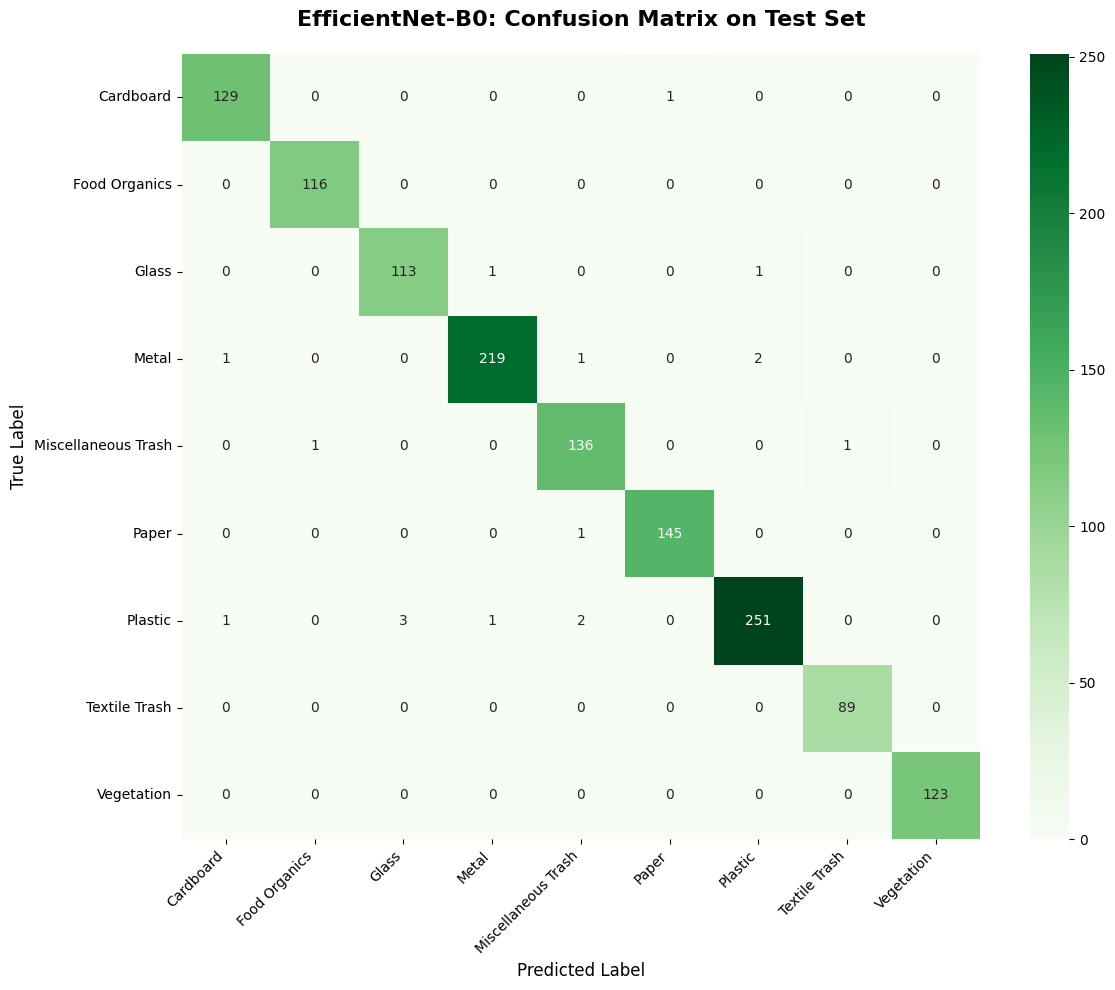

In [46]:
# Create test loader for EfficientNet (using its specific transforms)
efficientnet_test_dataset = datasets.ImageFolder(
    root=os.path.join(SPLIT_DATA_DIR, 'test'),
    transform=efficientnet_val_transform
)

efficientnet_test_loader = DataLoader(
    efficientnet_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Evaluating EfficientNet-B0 on Test Set...")
print("=" * 60)

# Evaluate on test set
efficientnet_b0.eval()
all_preds_eff = []
all_labels_eff = []
test_loss_eff = 0.0
correct_eff = 0
total_eff = 0

with torch.no_grad():
    for inputs, labels in efficientnet_test_loader:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        outputs = efficientnet_b0(inputs)
        loss = criterion_eff(outputs, labels)
        
        test_loss_eff += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, 1)
        total_eff += labels.size(0)
        correct_eff += (predicted == labels).sum().item()
        
        all_preds_eff.extend(predicted.cpu().numpy())
        all_labels_eff.extend(labels.cpu().numpy())

test_loss_eff = test_loss_eff / total_eff
test_acc_eff = correct_eff / total_eff

print(f"\nEfficientNet-B0 Test Results:")
print(f"  Test Loss:     {test_loss_eff:.4f}")
print(f"  Test Accuracy: {test_acc_eff:.4f} ({test_acc_eff*100:.2f}%)")
print(f"  Correct:       {correct_eff}/{total_eff}")
print("=" * 60)

# Classification Report
print("\nClassification Report (EfficientNet-B0):")
print(classification_report(all_labels_eff, all_preds_eff, target_names=class_names))

# Confusion Matrix
cm_eff = confusion_matrix(all_labels_eff, all_preds_eff)
plt.figure(figsize=(12, 10))
sns.heatmap(cm_eff, annot=True, fmt='d', cmap='Greens', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('EfficientNet-B0: Confusion Matrix on Test Set', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(PART2_DIR, 'efficientnet_confusion_matrix.png'), dpi=300, bbox_inches='tight')
print(f"\n✓ Confusion matrix saved to {PART2_DIR}/efficientnet_confusion_matrix.png")
plt.show()

## 24. Comprehensive Model Comparison

Now that we've trained and evaluated all three models (Custom CNN with Adam, ResNet-50, and EfficientNet-B0), let's create a comprehensive comparison to analyze their performance, efficiency, and suitability for waste classification.

✓ Comprehensive comparison saved to results\part2/all_models_comparison.png


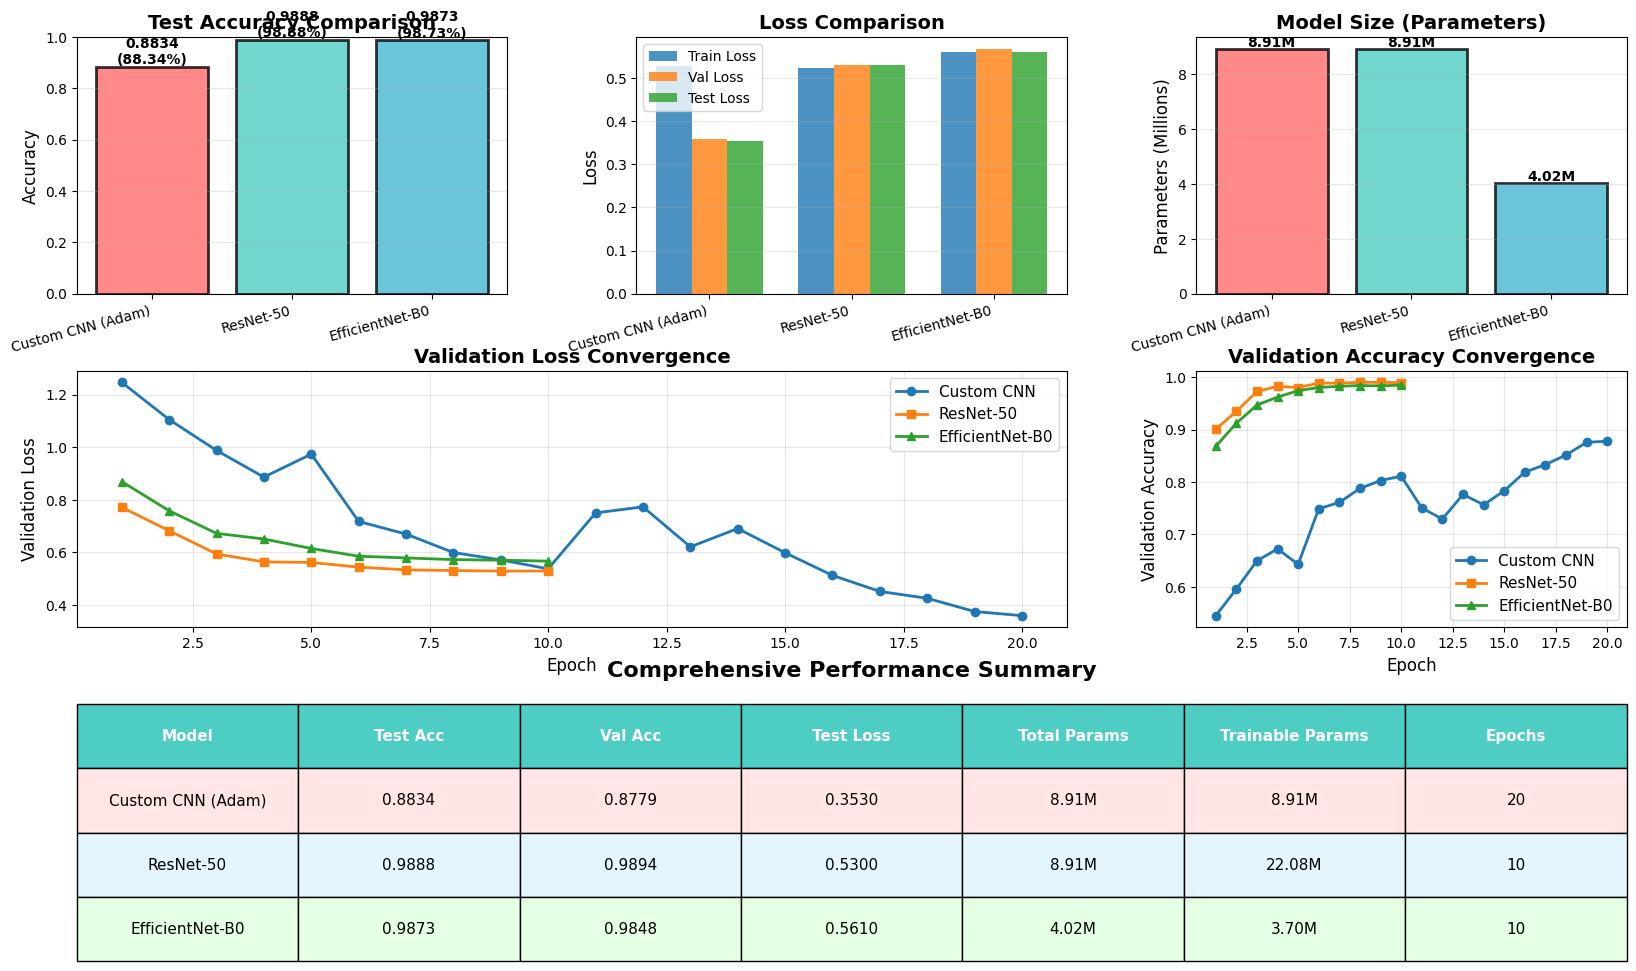


MODEL COMPARISON SUMMARY

Custom CNN (Adam):
  Test Accuracy:      0.8834 (88.34%)
  Validation Accuracy: 0.8779
  Test Loss:          0.3530
  Total Parameters:    8,913,161
  Training Epochs:     20

ResNet-50:
  Test Accuracy:      0.9888 (98.88%)
  Validation Accuracy: 0.9894
  Test Loss:          0.5300
  Total Parameters:    8,913,161
  Trainable Params:    22,081,545
  Training Epochs:     10

EfficientNet-B0:
  Test Accuracy:      0.9873 (98.73%)
  Validation Accuracy: 0.9848
  Test Loss:          0.5610
  Total Parameters:    4,019,077
  Trainable Params:    3,696,209
  Training Epochs:     10


In [47]:
# Collect all model results
models_comparison = {
    'Custom CNN (Adam)': {
        'train_acc': adam_history['train_acc'][-1],
        'val_acc': adam_history['val_acc'][-1],
        'test_acc': test_acc,
        'train_loss': adam_history['train_loss'][-1],
        'val_loss': adam_history['val_loss'][-1],
        'test_loss': test_loss,
        'params': sum(p.numel() for p in best_model.parameters()),
        'epochs': len(adam_history['train_acc'])
    },
    'ResNet-50': {
        'train_acc': resnet_history['train_acc'][-1],
        'val_acc': resnet_history['val_acc'][-1],
        'test_acc': test_acc_resnet,
        'train_loss': resnet_history['train_loss'][-1],
        'val_loss': resnet_history['val_loss'][-1],
        'test_loss': test_loss_resnet,
        'params': total_params,
        'trainable_params': trainable_params,
        'epochs': len(resnet_history['train_acc'])
    },
    'EfficientNet-B0': {
        'train_acc': efficientnet_history['train_acc'][-1],
        'val_acc': efficientnet_history['val_acc'][-1],
        'test_acc': test_acc_eff,
        'train_loss': efficientnet_history['train_loss'][-1],
        'val_loss': efficientnet_history['val_loss'][-1],
        'test_loss': test_loss_eff,
        'params': total_params_eff,
        'trainable_params': trainable_params_eff,
        'epochs': len(efficientnet_history['train_acc'])
    }
}

# Create comparison plots
fig = plt.figure(figsize=(20, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# 1. Test Accuracy Comparison
ax1 = fig.add_subplot(gs[0, 0])
model_names = list(models_comparison.keys())
test_accs = [models_comparison[m]['test_acc'] for m in model_names]
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
bars = ax1.bar(model_names, test_accs, color=colors, alpha=0.8, edgecolor='black', linewidth=2)
ax1.set_title('Test Accuracy Comparison', fontsize=14, fontweight='bold')
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.set_ylim([0, 1])
ax1.grid(True, alpha=0.3, axis='y')
for i, (bar, acc) in enumerate(zip(bars, test_accs)):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
             f'{acc:.4f}\n({acc*100:.2f}%)',
             ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=15, ha='right')

# 2. Loss Comparison (Train, Val, Test)
ax2 = fig.add_subplot(gs[0, 1])
x = np.arange(len(model_names))
width = 0.25
train_losses = [models_comparison[m]['train_loss'] for m in model_names]
val_losses = [models_comparison[m]['val_loss'] for m in model_names]
test_losses = [models_comparison[m]['test_loss'] for m in model_names]

ax2.bar(x - width, train_losses, width, label='Train Loss', alpha=0.8)
ax2.bar(x, val_losses, width, label='Val Loss', alpha=0.8)
ax2.bar(x + width, test_losses, width, label='Test Loss', alpha=0.8)
ax2.set_title('Loss Comparison', fontsize=14, fontweight='bold')
ax2.set_ylabel('Loss', fontsize=12)
ax2.set_xticks(x)
ax2.set_xticklabels(model_names)
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=15, ha='right')

# 3. Parameter Efficiency
ax3 = fig.add_subplot(gs[0, 2])
params_millions = [models_comparison[m]['params']/1e6 for m in model_names]
bars3 = ax3.bar(model_names, params_millions, color=colors, alpha=0.8, edgecolor='black', linewidth=2)
ax3.set_title('Model Size (Parameters)', fontsize=14, fontweight='bold')
ax3.set_ylabel('Parameters (Millions)', fontsize=12)
ax3.grid(True, alpha=0.3, axis='y')
for bar, param in zip(bars3, params_millions):
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height,
             f'{param:.2f}M',
             ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.setp(ax3.xaxis.get_majorticklabels(), rotation=15, ha='right')

# 4. Training Progress Comparison - Loss
ax4 = fig.add_subplot(gs[1, :2])
max_epochs = max([len(adam_history['train_loss']), 
                  len(resnet_history['train_loss']), 
                  len(efficientnet_history['train_loss'])])

ax4.plot(range(1, len(adam_history['val_loss'])+1), adam_history['val_loss'], 
         'o-', label='Custom CNN', linewidth=2, markersize=6)
ax4.plot(range(1, len(resnet_history['val_loss'])+1), resnet_history['val_loss'], 
         's-', label='ResNet-50', linewidth=2, markersize=6)
ax4.plot(range(1, len(efficientnet_history['val_loss'])+1), efficientnet_history['val_loss'], 
         '^-', label='EfficientNet-B0', linewidth=2, markersize=6)
ax4.set_title('Validation Loss Convergence', fontsize=14, fontweight='bold')
ax4.set_xlabel('Epoch', fontsize=12)
ax4.set_ylabel('Validation Loss', fontsize=12)
ax4.legend(fontsize=11)
ax4.grid(True, alpha=0.3)

# 5. Training Progress Comparison - Accuracy
ax5 = fig.add_subplot(gs[1, 2])
ax5.plot(range(1, len(adam_history['val_acc'])+1), adam_history['val_acc'], 
         'o-', label='Custom CNN', linewidth=2, markersize=6)
ax5.plot(range(1, len(resnet_history['val_acc'])+1), resnet_history['val_acc'], 
         's-', label='ResNet-50', linewidth=2, markersize=6)
ax5.plot(range(1, len(efficientnet_history['val_acc'])+1), efficientnet_history['val_acc'], 
         '^-', label='EfficientNet-B0', linewidth=2, markersize=6)
ax5.set_title('Validation Accuracy Convergence', fontsize=14, fontweight='bold')
ax5.set_xlabel('Epoch', fontsize=12)
ax5.set_ylabel('Validation Accuracy', fontsize=12)
ax5.legend(fontsize=11)
ax5.grid(True, alpha=0.3)

# 6. Performance Summary Table
ax6 = fig.add_subplot(gs[2, :])
ax6.axis('tight')
ax6.axis('off')

summary_data = []
for model_name in model_names:
    data = models_comparison[model_name]
    row = [
        model_name,
        f"{data['test_acc']:.4f}",
        f"{data['val_acc']:.4f}",
        f"{data['test_loss']:.4f}",
        f"{data['params']/1e6:.2f}M",
        f"{data.get('trainable_params', data['params'])/1e6:.2f}M",
        f"{data['epochs']}"
    ]
    summary_data.append(row)

table = ax6.table(cellText=summary_data,
                  colLabels=['Model', 'Test Acc', 'Val Acc', 'Test Loss', 
                            'Total Params', 'Trainable Params', 'Epochs'],
                  cellLoc='center',
                  loc='center',
                  bbox=[0, 0, 1, 1])

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2.5)

# Style the header
for i in range(7):
    table[(0, i)].set_facecolor('#4ECDC4')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Color code rows
for i in range(1, 4):
    for j in range(7):
        if i == 1:
            table[(i, j)].set_facecolor('#FFE5E5')
        elif i == 2:
            table[(i, j)].set_facecolor('#E5F5FF')
        else:
            table[(i, j)].set_facecolor('#E5FFE5')

ax6.set_title('Comprehensive Performance Summary', fontsize=16, fontweight='bold', pad=20)

plt.savefig(os.path.join(PART2_DIR, 'all_models_comparison.png'), dpi=300, bbox_inches='tight')
print(f"✓ Comprehensive comparison saved to {PART2_DIR}/all_models_comparison.png")
plt.show()

# Print summary
print("\n" + "="*80)
print("MODEL COMPARISON SUMMARY")
print("="*80)
for model_name in model_names:
    data = models_comparison[model_name]
    print(f"\n{model_name}:")
    print(f"  Test Accuracy:      {data['test_acc']:.4f} ({data['test_acc']*100:.2f}%)")
    print(f"  Validation Accuracy: {data['val_acc']:.4f}")
    print(f"  Test Loss:          {data['test_loss']:.4f}")
    print(f"  Total Parameters:    {data['params']:,}")
    if 'trainable_params' in data:
        print(f"  Trainable Params:    {data['trainable_params']:,}")
    print(f"  Training Epochs:     {data['epochs']}")
print("="*80)

## Discussion: Trade-offs, Advantages, and Limitations

Based on our comprehensive experiments and analysis, let's discuss the key findings and insights from comparing the custom CNN with state-of-the-art pre-trained models.

### Side-by-Side Confusion Matrix Comparison

In [ ]:
# Create side-by-side confusion matrix comparison
fig, axes = plt.subplots(1, 3, figsize=(24, 7))

# Custom CNN Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names, cbar_kws={'label': 'Count'})
axes[0].set_title(f'Custom CNN (Adam)\nTest Accuracy: {test_acc:.4f}', 
                  fontsize=14, fontweight='bold', pad=15)
axes[0].set_ylabel('True Label', fontsize=11)
axes[0].set_xlabel('Predicted Label', fontsize=11)
axes[0].tick_params(axis='x', rotation=45, labelsize=9)
axes[0].tick_params(axis='y', rotation=0, labelsize=9)

# ResNet-50 Confusion Matrix
sns.heatmap(cm_resnet, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=class_names, yticklabels=class_names, cbar_kws={'label': 'Count'})
axes[1].set_title(f'ResNet-50\nTest Accuracy: {test_acc_resnet:.4f}', 
                  fontsize=14, fontweight='bold', pad=15)
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].set_xlabel('Predicted Label', fontsize=11)
axes[1].tick_params(axis='x', rotation=45, labelsize=9)
axes[1].tick_params(axis='y', rotation=0, labelsize=9)

# EfficientNet-B0 Confusion Matrix
sns.heatmap(cm_eff, annot=True, fmt='d', cmap='Greens', ax=axes[2],
            xticklabels=class_names, yticklabels=class_names, cbar_kws={'label': 'Count'})
axes[2].set_title(f'EfficientNet-B0\nTest Accuracy: {test_acc_eff:.4f}', 
                  fontsize=14, fontweight='bold', pad=15)
axes[2].set_ylabel('True Label', fontsize=11)
axes[2].set_xlabel('Predicted Label', fontsize=11)
axes[2].tick_params(axis='x', rotation=45, labelsize=9)
axes[2].tick_params(axis='y', rotation=0, labelsize=9)

plt.suptitle('Confusion Matrix Comparison: All Models', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(PART2_DIR, 'all_confusion_matrices_comparison.png'), dpi=300, bbox_inches='tight')
print(f"✓ Confusion matrix comparison saved to {PART2_DIR}/all_confusion_matrices_comparison.png")
plt.show()

print("\n" + "="*80)
print("PART 2 COMPLETE!")
print("="*80)
print("\nAll transfer learning models have been trained and evaluated.")
print("Results saved in:", PART2_DIR)
print("\nKey Findings:")
print(f"  • Custom CNN Test Accuracy:      {test_acc:.4f}")
print(f"  • ResNet-50 Test Accuracy:       {test_acc_resnet:.4f}")
print(f"  • EfficientNet-B0 Test Accuracy: {test_acc_eff:.4f}")
print("="*80)